# N2H validation in mammalian cells

In [61]:
import glob
import xlrd
import pandas as pd
import numpy as np
import os
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

In [62]:
inputs_dir = "../1_inputs/N2H_validation"
allele_inputs = "../../../1_allele_collection/1_inputs"
outputs_dir = "../3_outputs/N2H_validation/mammalian_N2H"
sqy2h_outputs_dir = "../3_outputs/sqY2H"

nlr_detection_threshold = 2.23

## Wild type pairwise test

In [63]:
import warnings
warnings.simplefilter("ignore")

sheets = [f'Feuil{i}' for i in range (1, 22)]

wt_res = {'Exp1_1':dict(), 'Exp1_2':dict(), 'Exp2_1':dict(), 'Exp2_2':dict()}

for file_name in glob.glob(f'{inputs_dir}/mammalian_N2H/mN2H_WTPWT/data/*'):
    if 'N2H' in file_name:
        file_name = file_name.replace('~$','')
        xp = f'{file_name.split("_")[-1][:-7]}_{file_name.split("_")[-1][-6]}'

        for sheet in sheets:

            df =  pd.read_excel(file_name, sheet_name=sheet)
            df.rename(columns={c:c.lower() for c in df}, inplace=True)

            for dest_pla, dest_well, RawData, NA in zip(df.dest_pla, df['dest_well.1'], df['raw data'], df['unnamed: 13']):
                if NA != 1:
                    wt_res[xp][(dest_pla,dest_well)] = RawData
                else:
                    wt_res[xp][(dest_pla,dest_well)] = np.nan

In [64]:
# Read in the plate layout file
col = ['ad_orf_id', 'ad_symbol', 'db_orf_id',
       'db_symbol','variant_id', 'retest_pla', 'retest_pos', 
       'standard_batch']

retest_df = pd.read_csv(f'{inputs_dir}/mammalian_N2H/mapping_mn2h.csv', low_memory=False)
wt_df = retest_df[retest_df.standard_batch == 'N2HVUSWT'][col]

In [65]:
for xp in wt_res:
    wt_df[xp] = [wt_res[xp][(pla, pos)] for pla, pos in zip(wt_df.retest_pla, wt_df.retest_pos)]
    
wt_df.rename(columns={c:c.replace('ad','N1').replace('db','N2') for c in wt_df.columns}, inplace=True)
wt_df.rename(columns={'Exp1_1':'mN2H_xp1r1','Exp1_2':'mN2H_xp1r2','Exp2_1':'mN2H_xp2r1','Exp2_2':'mN2H_xp2r2'}, inplace=True)

wt_df['xp1'] = [np.mean([e for e in [r1,r2] if e == e]) if r1/r2 > 0.2 and r1/r2 < 5 else np.nan for r1,r2 in zip(wt_df.mN2H_xp1r1, wt_df.mN2H_xp1r2)]
wt_df['xp2'] = [np.mean([e for e in [r1,r2] if e == e]) if r1/r2 > 0.2 and r1/r2 < 5 else np.nan for r1,r2 in zip(wt_df.mN2H_xp2r1, wt_df.mN2H_xp2r2)]

In [66]:
# calculate normalized luminescence ratio
empty_N1_xp1_d = dict(zip(wt_df[wt_df.variant_id == 'empty_N1'].N2_orf_id, wt_df[wt_df.variant_id == 'empty_N1'].xp1))
empty_N2_xp1_d = dict(zip(wt_df[wt_df.variant_id == 'empty_N2'].N1_orf_id, wt_df[wt_df.variant_id == 'empty_N2'].xp1))

empty_N1_xp2_d = dict(zip(wt_df[wt_df.variant_id == 'empty_N1'].N2_orf_id, wt_df[wt_df.variant_id == 'empty_N1'].xp2))
empty_N2_xp2_d = dict(zip(wt_df[wt_df.variant_id == 'empty_N2'].N1_orf_id, wt_df[wt_df.variant_id == 'empty_N2'].xp2))

normalized_wt_df = wt_df[wt_df.variant_id.isin(['wt','RRS','PRS', 'allele'])].copy()

normalized_wt_df['empty_N1_xp1'] = normalized_wt_df.apply(lambda x: empty_N1_xp1_d[x.N2_orf_id], axis=1)
normalized_wt_df['empty_N2_xp1'] = normalized_wt_df.N1_orf_id.map(empty_N2_xp1_d)

normalized_wt_df['empty_N1_xp2'] = normalized_wt_df.apply(lambda x: empty_N1_xp2_d[x.N2_orf_id], axis=1)
normalized_wt_df['empty_N2_xp2'] = normalized_wt_df.N1_orf_id.map(empty_N2_xp2_d)

normalized_wt_df['NLR_xp1'] = [np.log2(N1N2/max([N1F2,N2F1])) for N1N2, N1F2, N2F1 in zip(normalized_wt_df.xp1, normalized_wt_df.empty_N1_xp1, normalized_wt_df.empty_N2_xp1)]
normalized_wt_df['NLR_xp2'] = [np.log2(N1N2/max([N1F2,N2F1])) for N1N2, N1F2, N2F1 in zip(normalized_wt_df.xp2, normalized_wt_df.empty_N1_xp2, normalized_wt_df.empty_N2_xp2)]

df = normalized_wt_df[normalized_wt_df.variant_id == 'RRS']
normalized_wt_df['zNLR1'] = normalized_wt_df.NLR_xp1.apply(lambda x: (x-np.mean(df.NLR_xp1))/np.std(df.NLR_xp1))
normalized_wt_df['zNLR2'] = normalized_wt_df.NLR_xp2.apply(lambda x: (x-np.mean(df.NLR_xp2))/np.std(df.NLR_xp2))

normalized_wt_df['NLR'] = normalized_wt_df.apply(lambda x: np.mean([x.NLR_xp1, x.NLR_xp2]), axis=1)

normalized_wt_df['pair'] = [tuple(sorted([n1,n2])) for n1,n2 in zip(normalized_wt_df.N1_symbol, normalized_wt_df.N2_symbol)]

In [131]:
normalized_wt_df.pair.nunique()

848

In [67]:
# Count the number detected by gene for different thresholds
normalized_wt_df['detected_0'] = normalized_wt_df.NLR.apply(lambda x: x > sorted(normalized_wt_df[normalized_wt_df.variant_id == 'RRS'].NLR.dropna().tolist())[-1])
normalized_wt_df['detected_1'] = normalized_wt_df.NLR.apply(lambda x: x > sorted(normalized_wt_df[normalized_wt_df.variant_id == 'RRS'].NLR.dropna().tolist())[-2])
normalized_wt_df['detected_2'] = normalized_wt_df.NLR.apply(lambda x: x > sorted(normalized_wt_df[normalized_wt_df.variant_id == 'RRS'].NLR.dropna().tolist())[-3])
normalized_wt_df['detected_3'] = normalized_wt_df.NLR.apply(lambda x: x > sorted(normalized_wt_df[normalized_wt_df.variant_id == 'RRS'].NLR.dropna().tolist())[-4])

by_gene_df = pd.DataFrame([pd.Series(dict(normalized_wt_df[(normalized_wt_df.variant_id == 'wt')].N2_symbol.value_counts())),
                           pd.Series(normalized_wt_df[normalized_wt_df.detected_0 & (normalized_wt_df.variant_id == 'wt')].N2_symbol.value_counts()),
                           pd.Series(normalized_wt_df[normalized_wt_df.detected_1 & (normalized_wt_df.variant_id == 'wt')].N2_symbol.value_counts()),
                           pd.Series(normalized_wt_df[normalized_wt_df.detected_2 & (normalized_wt_df.variant_id == 'wt')].N2_symbol.value_counts()),
                           pd.Series(normalized_wt_df[normalized_wt_df.detected_3 & (normalized_wt_df.variant_id == 'wt')].N2_symbol.value_counts())
                           
                          ]).T

by_gene_df.columns = ['y2h', 'mn2h_0','mn2h_1','mn2h_2', 'mn2h_3']
by_gene_df.fillna(0, inplace=True)
by_gene_df.sort_values(by='mn2h_0', ascending=False, inplace=True)

In [68]:
# Write out files
normalized_wt_df.to_csv(f'{outputs_dir}/mN2H_wtpwt_raw.csv')
by_gene_df.to_csv(f'{outputs_dir}/mN2H_wtpwt_counts.csv')

normalized_wt_df[(normalized_wt_df.detected_3 == True) & (normalized_wt_df.variant_id == 'wt')].to_csv(f'{outputs_dir}/mN2H_wtpwt_positive_PPIs.csv') 

## Allele pairwise test

In [69]:
# Dictionaries to map plate layouts
xp1_mapping_d = {i: ((i - 1) // 3 + 1, (i - 1) % 3 + 1) for i in range(1, 70)}

xp2_mapping_d = {
    1: (1,1),  2: (1,2),  3: (1,3),  4: (2,1),  5: (2,2),  6: (2,3),  
    7: (3,1),  8: (3,2),  9: (3,3), 10: (4,1), 11: (4,2), 12: (4,3),  
    13: (7,1), 14: (7,2), 15: (7,3), 16: (6,1), 17: (6,2), 18: (6,3),  
    19: (5,1), 20: (5,2), 21: (5,3), 22: (9,1), 23: (9,2), 24: (9,3),  
    25: (10,1), 26: (10,2), 27: (10,3), 28: (11,1), 29: (11,2), 30: (11,3),  
    31: (12,1), 32: (12,2), 33: (12,3), 34: (13,1), 35: (13,2), 36: (13,3),  
    37: (14,1), 38: (14,2), 39: (14,3), 40: (15,1), 41: (15,2), 42: (15,3),  
    43: (16,1), 44: (16,2), 45: (16,3), 46: (17,1), 47: (17,2), 48: (17,3),  
    49: (18,1), 50: (18,2), 51: (18,3), 52: (19,1), 53: (19,2), 54: (19,3),  
    55: (20,1), 56: (20,2), 57: (20,3), 58: (21,1), 59: (21,2), 60: (21,3),  
    61: (22,1), 62: (22,2), 63: (22,3), 64: (23,1), 65: (23,2), 66: (23,3),  
    67: (8,1), 68: (8,2), 69: (8,3)
}

In [70]:
# Load in raw data for allele pairwise test (apwt) from the mammalian N2H validation assay
res = {'xp1':{1:{},2:{},3:{}},
        'xp2':{1:{},2:{},3:{}}
        }

for rep_id in ['1','2']:
    for i,elem in enumerate(glob.glob(f'{inputs_dir}/mammalian_N2H/mN2H_APWT/N2H_raw_replicat0{rep_id}/*')):
        pla = int(elem.split('-')[-1][1:-4])
        retest_pla, repeat = xp1_mapping_d[pla] if rep_id == '1' else xp2_mapping_d[pla]

        wb = xlrd.open_workbook(elem, encoding_override='ascii')  #ascii  #'iso-8859-1'
        df = pd.read_excel(wb, skiprows=24, skipfooter=0)
        if len(df) > 8:
            df = pd.read_excel(wb, skiprows=35, skipfooter=10)

        df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)

        value_d = dict()
        for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
            for i, value in enumerate(row):
                key = (retest_pla,f'{l}{str(i+1).zfill(2)}')

                res[f'xp{rep_id}'][repeat][key] = value

In [71]:
# Read in the plate layout file
retest_df = pd.read_csv(f'{inputs_dir}/mammalian_N2H/mapping_mn2h.csv', low_memory=False)
retest_df = retest_df[retest_df.standard_batch == 'mN2Hapwtv2'].copy()
retest_df.rename(columns={c:c.replace('ad','N1').replace('db','N2') for c in retest_df.columns},inplace=True)

# Calculate normalized luminescence ratio
for xp in ['xp1','xp2']:
    for rep in [1,2,3]:
        retest_df[f'mN2H_{xp}r{rep}'] = [res[xp][rep][pla,pos] if (pla,pos) in res[xp][rep] else np.nan for pla,pos in zip(retest_df.retest_pla, retest_df.retest_pos)]

#discard measure if signal is 20% of those of 2 other replicates (it's never 5 fold more than the 2 other measures)    
retest_df['mN2H_xp1r1'] = [np.nan if r1/r2<0.2 and r1/r3<0.2 else r1 for r1,r2,r3 in zip(retest_df.mN2H_xp1r1, retest_df.mN2H_xp1r2, retest_df.mN2H_xp1r3)]
retest_df['mN2H_xp1r2'] = [np.nan if r2/r1<0.2 and r2/r3<0.2 else r2 for r1,r2,r3 in zip(retest_df.mN2H_xp1r1, retest_df.mN2H_xp1r2, retest_df.mN2H_xp1r3)]
retest_df['mN2H_xp1r3'] = [np.nan if r3/r2<0.2 and r3/r1<0.2 else r3 for r1,r2,r3 in zip(retest_df.mN2H_xp1r1, retest_df.mN2H_xp1r2, retest_df.mN2H_xp1r3)]
retest_df['mN2H_xp2r1'] = [np.nan if r1/r2<0.2 and r1/r3<0.2 else r1 for r1,r2,r3 in zip(retest_df.mN2H_xp2r1, retest_df.mN2H_xp2r2, retest_df.mN2H_xp2r3)]
retest_df['mN2H_xp2r2'] = [np.nan if r2/r1<0.2 and r2/r3<0.2 else r2 for r1,r2,r3 in zip(retest_df.mN2H_xp2r1, retest_df.mN2H_xp2r2, retest_df.mN2H_xp2r3)]
retest_df['mN2H_xp2r3'] = [np.nan if r3/r2<0.2 and r3/r1<0.2 else r3 for r1,r2,r3 in zip(retest_df.mN2H_xp2r1, retest_df.mN2H_xp2r2, retest_df.mN2H_xp2r3)]

xp_errors = {1:{(5,'E03')},
                2:{(5,'E03'),
                (13,'A05'),
                (13,'A06'),
                (13,'D06'),
                (14,'C01'),
                (14,'B04'),
                (14,'E06'),
                (14,'H06'),
                (14,'B08'),
                (14,'A10'),
                }
            }

retest_df['error1'] = [(p,w) in [(pla,well) for pla,well in xp_errors[1]] for p,w in zip(retest_df.retest_pla, retest_df.retest_pos)]
retest_df['error2'] = [(p,w) in [(pla,well) for pla,well in xp_errors[2]] for p,w in zip(retest_df.retest_pla, retest_df.retest_pos)]

retest_df['xp1'] = [np.mean([e for e in [r1,r2,r3] if e == e]) for r1,r2,r3 in zip(retest_df.mN2H_xp1r1, retest_df.mN2H_xp1r2, retest_df.mN2H_xp1r3)]
retest_df['xp2'] = [np.mean([e for e in [r1,r2,r3] if e == e]) for r1,r2,r3 in zip(retest_df.mN2H_xp2r1, retest_df.mN2H_xp2r2, retest_df.mN2H_xp2r3)]

retest_df['xp1'] = [xp1 if not error else np.nan for xp1,error in zip(retest_df.xp1, retest_df.error1)]
retest_df['xp2'] = [xp2 if not error else np.nan for xp2,error in zip(retest_df.xp2, retest_df.error2)]

retest_df['xp_mean'] = [np.mean([xp1, xp2]) for xp1, xp2 in zip(retest_df.xp1, retest_df.xp2)]

In [72]:
# 1) Compute WT xp mean for empty_N1 variant per plate and N2_orf_id
empty1 = retest_df[retest_df.variant_id == 'empty_N1']
wt_map = (
    empty1[empty1['N2_mut_id'] == 0]
    .groupby(['retest_pla', 'N2_orf_id'])['xp_mean']
    .mean()
    .rename('wt_xp_mean')
    .reset_index()
)

# 2) Merge back into the empty1 subset and compute log10FC
empty1 = empty1.merge(wt_map, on=['retest_pla', 'N2_orf_id'], how='left')
empty1['log10fc_empty_N1'] = np.log10(empty1['xp_mean'] / empty1['wt_xp_mean'])

# 3) Attach this new column to the full retest_df
retest_df = retest_df.merge(
    empty1[['retest_pla', 'N2_orf_id', 'N2_mut_id', 'log10fc_empty_N1']],
    on=['retest_pla', 'N2_orf_id', 'N2_mut_id'],
    how='left'
)


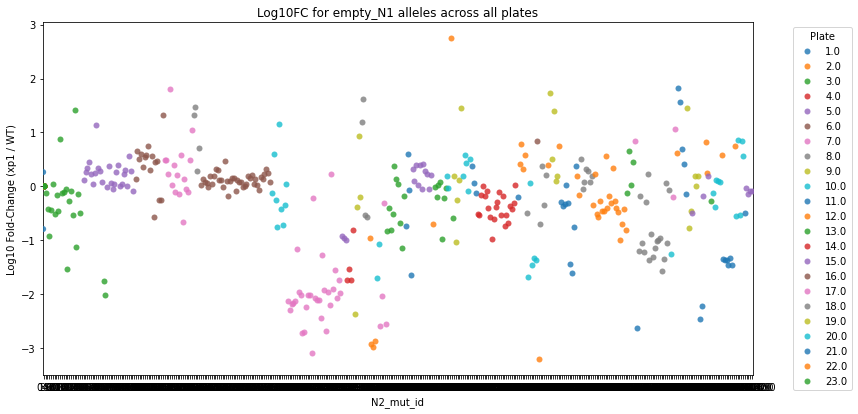

In [73]:
# 4) Plot all log10FC on a single stripplot, coloring by plate
plt.figure(figsize=(12, 6))
sns.stripplot(
    data=empty1, 
    x='N2_mut_id', 
    y='log10fc_empty_N1', 
    hue='retest_pla', 
    dodge=True, 
    jitter=0.2, 
    palette='tab10',
    size=6,
    alpha=0.8
)
plt.xlabel('N2_mut_id')
plt.ylabel('Log10 Fold‑Change (xp1 / WT)')
plt.title('Log10FC for empty_N1 alleles across all plates')
plt.legend(title='Plate', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [77]:

# Old version established by Jess and Flo

# empty_N1_xp1_d = dict(zip(zip(retest_df[retest_df.variant_id == 'empty_N1'].N2_orf_id,retest_df[retest_df.variant_id == 'empty_N1'].N2_mut_id),retest_df[retest_df.variant_id == 'empty_N1'].xp1))
# empty_N2_xp1_d = dict(zip(retest_df[retest_df.variant_id == 'empty_N2'].N1_orf_id, retest_df[retest_df.variant_id == 'empty_N2'].xp1))

# empty_N1_xp2_d = dict(zip(zip(retest_df[retest_df.variant_id == 'empty_N1'].N2_orf_id,retest_df[retest_df.variant_id == 'empty_N1'].N2_mut_id),retest_df[retest_df.variant_id == 'empty_N1'].xp2))
# empty_N2_xp2_d = dict(zip(retest_df[retest_df.variant_id == 'empty_N2'].N1_orf_id, retest_df[retest_df.variant_id == 'empty_N2'].xp2))



# Max fix - above is not taking empty replicates into account, the dict-zip approach only consider the last measurement

# empty_N1_xp1_d = {}

# for (N2_orf_id, N2_mut_id), df in retest_df[retest_df.variant_id == 'empty_N1'].groupby(['N2_orf_id', 'N2_mut_id']):
#     empty_N1_xp1_d[(N2_orf_id, N2_mut_id)] = np.mean(df.xp1)

# empty_N1_xp2_d = {}

# for (N2_orf_id, N2_mut_id), df in retest_df[retest_df.variant_id == 'empty_N1'].groupby(['N2_orf_id', 'N2_mut_id']):
#     empty_N1_xp2_d[(N2_orf_id, N2_mut_id)] = np.mean(df.xp2)
    
# empty_N2_xp1_d = {}

# for N1_orf_id, df in retest_df[retest_df.variant_id == 'empty_N2'].groupby('N1_orf_id'):
#     empty_N2_xp1_d[N1_orf_id] = np.mean(df.xp1)

# empty_N2_xp2_d = {}

# for N1_orf_id, df in retest_df[retest_df.variant_id == 'empty_N2'].groupby('N1_orf_id'):
#     empty_N2_xp2_d[N1_orf_id] = np.mean(df.xp2)

# Continue

# second approach, per plate

empty_N1_xp1_d = {}

for (N2_orf_id, N2_mut_id, retest_pla), df in retest_df[retest_df.variant_id == 'empty_N1'].groupby(['N2_orf_id', 'N2_mut_id', 'retest_pla']):
    empty_N1_xp1_d[(N2_orf_id, N2_mut_id, retest_pla)] = np.mean(df.xp1)

empty_N1_xp2_d = {}

for (N2_orf_id, N2_mut_id, retest_pla), df in retest_df[retest_df.variant_id == 'empty_N1'].groupby(['N2_orf_id', 'N2_mut_id', 'retest_pla']):
    empty_N1_xp2_d[(N2_orf_id, N2_mut_id, retest_pla)] = np.mean(df.xp2)
    
empty_N2_xp1_d = {}

for (N1_orf_id, retest_pla), df in retest_df[retest_df.variant_id == 'empty_N2'].groupby(['N1_orf_id','retest_pla']):
    empty_N2_xp1_d[(N1_orf_id, retest_pla)] = np.mean(df.xp1)

empty_N2_xp2_d = {}

for (N1_orf_id, retest_pla), df in retest_df[retest_df.variant_id == 'empty_N2'].groupby(['N1_orf_id','retest_pla']):
    empty_N2_xp2_d[(N1_orf_id, retest_pla)] = np.mean(df.xp2)



normalized_df = retest_df[retest_df.variant_id.isin(['wt','RRS','PRS', 'allele'])].copy()

normalized_df.drop(columns=['error1','error2','mN2H_xp1r1','mN2H_xp1r2','mN2H_xp1r3','mN2H_xp2r1','mN2H_xp2r2','mN2H_xp2r3'], inplace=True)

# normalized_df['empty_N1_xp1'] = normalized_df.apply(lambda x: empty_N1_xp1_d[x.N2_orf_id,x.N2_mut_id], axis=1)
# normalized_df['empty_N2_xp1'] = normalized_df.N1_orf_id.map(empty_N2_xp1_d)

# normalized_df['empty_N1_xp2'] = normalized_df.apply(lambda x: empty_N1_xp2_d[x.N2_orf_id,x.N2_mut_id], axis=1)
# normalized_df['empty_N2_xp2'] = normalized_df.N1_orf_id.map(empty_N2_xp2_d)

# apply the pla method

normalized_df['empty_N1_xp1'] = normalized_df.apply(lambda x: empty_N1_xp1_d[x.N2_orf_id,x.N2_mut_id,x.retest_pla], axis=1)
normalized_df['empty_N2_xp1'] = normalized_df.apply(lambda x: empty_N2_xp1_d[x.N1_orf_id,x.retest_pla], axis=1)

normalized_df['empty_N1_xp2'] = normalized_df.apply(lambda x: empty_N1_xp2_d[x.N2_orf_id,x.N2_mut_id, x.retest_pla], axis=1)
normalized_df['empty_N2_xp2'] = normalized_df.apply(lambda x: empty_N2_xp2_d[x.N1_orf_id,x.retest_pla], axis=1)

# test for the empty based on z-score

# normalized_df['z_empty_N1_xp1'] = normalized_df.empty_N1_xp1.apply(lambda x: (np.log10(x)-empty_mean)/empty_std)
# normalized_df['z_empty_N2_xp1'] = normalized_df.empty_N2_xp1.apply(lambda x: (np.log10(x)-empty_mean)/empty_std)

# normalized_df['z_empty_N1_xp2'] = normalized_df.empty_N1_xp2.apply(lambda x: (np.log10(x)-empty_mean)/empty_std)
# normalized_df['z_empty_N2_xp2'] = normalized_df.empty_N2_xp2.apply(lambda x: (np.log10(x)-empty_mean)/empty_std)

# zcols = [
#     'z_empty_N1_xp1','z_empty_N2_xp1',
#     'z_empty_N1_xp2','z_empty_N2_xp2'
# ]

# mask = normalized_df[zcols].abs().le(2).all(axis=1)

# normalized_df = normalized_df[mask].copy()

##

normalized_df['max_ctrl_r1'] = [max([en1,en2]) for en1, en2 in zip(normalized_df.empty_N1_xp1, normalized_df.empty_N2_xp1)]
normalized_df['max_ctrl_r2'] = [max([en1,en2]) for en1, en2 in zip(normalized_df.empty_N1_xp2, normalized_df.empty_N2_xp2)]

normalized_df['NLR1'] = [N1N2/max([N1F2,N2F1]) for N1N2, N1F2, N2F1 in zip(normalized_df.xp1, normalized_df.empty_N1_xp1, normalized_df.empty_N2_xp1)]
normalized_df['NLR2'] = [N1N2/max([N1F2,N2F1]) for N1N2, N1F2, N2F1 in zip(normalized_df.xp2, normalized_df.empty_N1_xp2, normalized_df.empty_N2_xp2)]

d = {0:1,1:0}
normalized_df['repeat_ratio'] = [[nlr1,nlr2][i%2]/[nlr1,nlr2][d[(i%2)]] for i,(nlr1, nlr2) in enumerate(zip(normalized_df.NLR1, normalized_df.NLR2))]
normalized_df['repeat_ratio_log2'] = normalized_df.repeat_ratio.apply(np.log2)

normalized_df['avg_NLR'] = [np.mean([nlr1, nlr2]) for nlr1,nlr2 in zip(normalized_df.NLR1, normalized_df.NLR2)]

# Max add
normalized_df['pair'] = list(zip(normalized_df.N2_orf_id, normalized_df.N1_orf_id))

std_nlr_variation = np.std(normalized_df['repeat_ratio_log2'])
avg_nlr_variation = np.mean(normalized_df['repeat_ratio_log2'])

normalized_df['repeat_zscore'] = normalized_df.repeat_ratio_log2.apply(lambda x: abs((x-avg_nlr_variation)/std_nlr_variation) >= 1)


In [114]:
df_wt= normalized_df.query("variant_id == 'wt'")


In [78]:
# Get perturbation z-scores
allele_df = normalized_df.query("variant_id == 'allele' and ~avg_NLR.isnull()").copy()

df = normalized_df.query("variant_id == 'wt'")
wt_NLR_d = {(r.N2_orf_id, r.N1_orf_id):r.avg_NLR for i,r in df.iterrows()}


allele_df['avg_WT_NLR'] = [wt_NLR_d.get((N2,N1), np.nan) for N2,N1 in zip(allele_df.N2_orf_id, allele_df.N1_orf_id)]
allele_df = allele_df[~allele_df.avg_WT_NLR.isnull()].copy() #remove only one allele-WT
allele_df['AWT_ratio'] = allele_df.avg_NLR / allele_df.avg_WT_NLR

# Max add - Above approach doesn't take into account that multiple alleles/wt span across multiple plates
wt_pla_d = {((r.N2_orf_id, r.N1_orf_id), r.retest_pla):r.avg_NLR for _, r in df.iterrows()}
allele_df['avg_WT_NLR_pla'] = [wt_pla_d.get(((N2,N1),pla), np.nan) for N2,N1,pla in zip(allele_df.N2_orf_id, allele_df.N1_orf_id, allele_df.retest_pla)]
allele_df['AWT_ratio_pla'] = allele_df.avg_NLR / allele_df.avg_WT_NLR_pla
allele_df['log2fc'] = np.log2(allele_df.avg_NLR / allele_df.avg_WT_NLR_pla)

# Continue

df = normalized_df.query("variant_id == 'RRS' and avg_NLR < 200")
l = [np.mean([nlr1,nlr2]) for nlr1,nlr2 in zip(df.NLR1, df.NLR2) if nlr1 == nlr1 and nlr2 == nlr2]
std_rrs, mean_rrs = np.std(l), np.mean(l)
allele_df['z_WT_NLR'] = allele_df.avg_WT_NLR.apply(lambda x: (x-mean_rrs)/std_rrs)
allele_df['WT_detected'] = allele_df.z_WT_NLR.apply(lambda x: x >= nlr_detection_threshold)

# Max add

allele_df['z_WT_NLR_pla'] = allele_df.avg_WT_NLR_pla.apply(lambda x: (x-mean_rrs)/std_rrs)
allele_df['WT_detected_pla'] = allele_df.z_WT_NLR_pla.apply(lambda x: x >= 2.326)


std_ratio = np.std(normalized_df.repeat_ratio_log2)
mean_ratio = np.mean(normalized_df.repeat_ratio_log2)
allele_df['z_perturbation'] = allele_df.AWT_ratio.apply(lambda x: (np.log2(x)-mean_ratio)/std_ratio)
allele_df['z_cat'] = ['not_detected' if not wt_detected else 'increase_ppi' if zp>=1.96 else 'decrease_ppi' if zp<=-1.96 else 'no_perturbation' for zp,wt_detected in zip(allele_df.z_perturbation, allele_df.WT_detected)] 

In [127]:
allele_df

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,WT_detected_pla,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,fc_class
0,93035.0,2838,TMEM248,NaN,9634,CLDN19,216880,5.0,A08,mN2Hapwtv2,...,False,1.311307,not_detected,1,1,NaN,NaN,NaN,NaN,Moderate increase
1,93037.0,1198,TNFSF14,NaN,9634,CLDN19,216880,5.0,C08,mN2Hapwtv2,...,True,0.723639,no_perturbation,1,1,NaN,NaN,NaN,NaN,Weak increase
2,93043.0,7201,RAD51D,NaN,13571,XRCC2,218098,5.0,A09,mN2Hapwtv2,...,True,-0.851622,no_perturbation,1,1,NaN,NaN,NaN,NaN,Weak decrease
3,93044.0,9955,FCGR1A,NaN,9634,CLDN19,216880,5.0,B09,mN2Hapwtv2,...,True,1.691502,no_perturbation,1,1,NaN,NaN,NaN,NaN,Moderate increase
4,93045.0,56141,KRT31,NaN,55855,KRT2,219419,5.0,C09,mN2Hapwtv2,...,False,4.002171,not_detected,1,1,inf,False,WT edge lost,WT edge lost,Strong increase
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
559,94622.0,1256,KLHL3,NaN,11305,CUL3,217226,22.0,G11,mN2Hapwtv2,...,False,-5.002487,not_detected,1,1,NaN,NaN,NaN,NaN,Strong decrease
560,94630.0,3608,CYB561,NaN,3086,GOSR2,201084,22.0,G12,mN2Hapwtv2,...,False,4.876476,not_detected,1,1,NaN,NaN,NaN,NaN,Strong increase
561,94635.0,361,GRAMD2B,NaN,3438,TMEM43,201177,23.0,E01,mN2Hapwtv2,...,True,-0.203351,no_perturbation,1,1,1.000,False,WT-like,WT-like,Neutral
562,94674.0,361,GRAMD2B,NaN,3438,TMEM43,201179,23.0,D06,mN2Hapwtv2,...,True,-0.554115,no_perturbation,1,1,0.000,True,edge lost,edge lost,Weak decrease


In [121]:
allele_df[allele_df.N2_symbol == 'STXBP1'].retest_pla.unique()

array([6., 7., 8.])

In [122]:
allele_df[allele_df.N2_symbol == 'PLP1'].retest_pla.unique()

array([ 9., 10., 11.])

In [117]:
allele_df.N2_symbol.value_counts()

N2_symbol
PLP1       120
STXBP1     116
GFAP        50
MLH1        32
TPM1        28
MVK         27
TH          22
SFTPC       20
KRT8        18
KRT6A       18
PYGL        13
KRT86       10
PMP22        9
PNKP         6
GALE         6
CLDN19       6
KCTD1        5
SIX1         4
NMNAT1       4
BAG3         4
KRT2         4
THAP1        4
PITX2        4
DOLK         4
TMEM43       3
GOSR2        3
CUL3         3
KLHL3        3
TPM3         3
PRPS1        2
FBP1         2
TPK1         1
NEUROG3      1
RP2          1
VAPB         1
ZMYND10      1
PHYKPL       1
LDHB         1
NAA10        1
PUF60        1
XRCC2        1
MID1         1
Name: count, dtype: int64

In [116]:
df_wt[df_wt.N2_orf_id == 4062]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,empty_N2_xp2,max_ctrl_r1,max_ctrl_r2,NLR1,NLR2,repeat_ratio,repeat_ratio_log2,avg_NLR,pair,repeat_zscore
727,93326.0,2012.0,LHFPL5,NaN,4062.0,PLP1,0.0,9.0,E01,mN2Hapwtv2,...,8.235337e+05,5.588993e+05,8.235337e+05,0.627957,0.628524,1.000902,0.001301,0.628241,"(4062.0, 2012.0)",False
755,93354.0,4935.0,SLC18A1,NaN,4062.0,PLP1,0.0,9.0,A05,mN2Hapwtv2,...,3.699860e+05,1.653637e+05,3.699860e+05,7.180432,3.908407,1.837176,0.877490,5.544419,"(4062.0, 4935.0)",False
756,93355.0,4946.0,PTPRN,NaN,4062.0,PLP1,0.0,9.0,B05,mN2Hapwtv2,...,6.556300e+04,2.297650e+04,6.556300e+04,134.877099,96.768284,0.717455,-0.479039,115.822692,"(4062.0, 4946.0)",False
759,93358.0,11621.0,MTIF3,NaN,4062.0,PLP1,0.0,9.0,E05,mN2Hapwtv2,...,1.852703e+05,8.824400e+04,1.852703e+05,1.152373,1.434113,0.803544,-0.315551,1.293243,"(4062.0, 11621.0)",False
778,93377.0,12825.0,CLDN20,NaN,4062.0,PLP1,0.0,9.0,H07,mN2Hapwtv2,...,7.124107e+05,3.922750e+05,7.124107e+05,0.677892,0.815707,1.203300,0.266997,0.746800,"(4062.0, 12825.0)",False
787,93386.0,6446.0,ERGIC3,NaN,4062.0,PLP1,0.0,9.0,A09,mN2Hapwtv2,...,7.085667e+03,1.434667e+03,7.085667e+03,249.191682,69.310533,0.278141,-1.846109,159.251108,"(4062.0, 6446.0)",True
801,93400.0,8186.0,CLEC2D,NaN,4062.0,PLP1,0.0,9.0,G10,mN2Hapwtv2,...,1.533589e+06,4.433267e+05,1.533589e+06,6.905406,3.016203,0.436789,-1.194992,4.960805,"(4062.0, 8186.0)",True
804,93403.0,13628.0,KLRC1,NaN,4062.0,PLP1,0.0,9.0,B11,mN2Hapwtv2,...,2.675346e+06,9.874137e+05,2.675346e+06,3.512025,2.837786,1.237593,0.307537,3.174905,"(4062.0, 13628.0)",False
805,93404.0,5793.0,MS4A3,NaN,4062.0,PLP1,0.0,9.0,C11,mN2Hapwtv2,...,4.386000e+03,3.423500e+03,4.386000e+03,64.603476,79.789482,1.235065,0.304587,72.196479,"(4062.0, 5793.0)",False
807,93406.0,11130.0,SLC35E3,NaN,4062.0,PLP1,0.0,9.0,E11,mN2Hapwtv2,...,1.695063e+05,8.764800e+04,1.695063e+05,19.903272,19.195312,0.964430,-0.052252,19.549292,"(4062.0, 11130.0)",False


In [79]:
# Incorporate sequence confirmation results
seq_N1 = pd.read_csv(f"{inputs_dir}/N2H_sequencing_confirmation/N2H_validation_nodes_validation_interactor.tsv", sep="\t")
seq_N2 = pd.read_csv(f"{inputs_dir}/N2H_sequencing_confirmation/N2H_validation_nodes_validation_allele.tsv", sep="\t")

seq_N1 = seq_N1[seq_N1["seq_confirmation"] == 1][["seq_confirmation", "orf_id"]]
seq_N2 = seq_N2[seq_N2["seq_confirmation"] == 1][["seq_confirmation", "orf_id", "mut_id"]]

seq_N1.rename(columns={"orf_id": "N1_orf_id", "seq_confirmation": "N1_conf"}, inplace=True)
seq_N2.rename(columns={"orf_id": "N2_orf_id", "mut_id": "N2_mut_id", "seq_confirmation": "N2_conf"}, inplace=True)

allele_df = allele_df.astype({"N1_orf_id": int, "N2_orf_id": int, "N2_mut_id": int})

# Only keep pairs where both proteins are sequenced confirmed
print(allele_df.shape)
allele_df = pd.merge(allele_df, seq_N1, on="N1_orf_id")
print(allele_df.shape)
allele_df = pd.merge(allele_df, seq_N2, on=["N2_orf_id", "N2_mut_id"])
print(allele_df.shape)

(822, 46)
(803, 47)
(564, 48)


In [80]:
# Add perturbation class from sqY2H

perturb_df = pd.read_csv(f'{sqy2h_outputs_dir}/7_edge_perturbation_categorical.csv')
perturb_df.rename(columns={c:c.replace('ad','N1').replace('db','N2') for c in perturb_df.columns}, inplace=True)

cols_to_keep = ['N1_orf_id', 'N2_orf_id', 'N2_mut_id', 'ratio', 'perturbed', 'perturbation_classes', 'perturbation_classes_2']

perturb_df = perturb_df[cols_to_keep]
allele_df = pd.merge(allele_df, perturb_df, on=['N1_orf_id', 'N2_orf_id', 'N2_mut_id'], how='left')
allele_df

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,z_WT_NLR_pla,WT_detected_pla,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2
0,93035.0,2838,TMEM248,NaN,9634,CLDN19,216880,5.0,A08,mN2Hapwtv2,...,0.783132,False,1.311307,not_detected,1,1,NaN,NaN,NaN,NaN
1,93037.0,1198,TNFSF14,NaN,9634,CLDN19,216880,5.0,C08,mN2Hapwtv2,...,5.551872,True,0.723639,no_perturbation,1,1,NaN,NaN,NaN,NaN
2,93043.0,7201,RAD51D,NaN,13571,XRCC2,218098,5.0,A09,mN2Hapwtv2,...,23.887663,True,-0.851622,no_perturbation,1,1,NaN,NaN,NaN,NaN
3,93044.0,9955,FCGR1A,NaN,9634,CLDN19,216880,5.0,B09,mN2Hapwtv2,...,6.435619,True,1.691502,no_perturbation,1,1,NaN,NaN,NaN,NaN
4,93045.0,56141,KRT31,NaN,55855,KRT2,219419,5.0,C09,mN2Hapwtv2,...,0.391161,False,4.002171,not_detected,1,1,inf,False,WT edge lost,WT edge lost
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
559,94622.0,1256,KLHL3,NaN,11305,CUL3,217226,22.0,G11,mN2Hapwtv2,...,-0.151163,False,-5.002487,not_detected,1,1,NaN,NaN,NaN,NaN
560,94630.0,3608,CYB561,NaN,3086,GOSR2,201084,22.0,G12,mN2Hapwtv2,...,-0.596915,False,4.876476,not_detected,1,1,NaN,NaN,NaN,NaN
561,94635.0,361,GRAMD2B,NaN,3438,TMEM43,201177,23.0,E01,mN2Hapwtv2,...,7.546597,True,-0.203351,no_perturbation,1,1,1.000,False,WT-like,WT-like
562,94674.0,361,GRAMD2B,NaN,3438,TMEM43,201179,23.0,D06,mN2Hapwtv2,...,7.546597,True,-0.554115,no_perturbation,1,1,0.000,True,edge lost,edge lost


In [81]:
# Write out final file
allele_df.to_csv(f'{outputs_dir}/mN2H_apwt_allele_df.csv')

# log2fc

In [82]:
def classify_log2fc(x):
    if x <= -2:
        return 'Strong decrease'
    elif x <= -1:
        return 'Moderate decrease'
    elif x <= -0.5:
        return 'Weak decrease'
    elif x < 0.5:
        return 'Neutral'
    elif x < 1:
        return 'Weak increase'
    elif x < 2:
        return 'Moderate increase'
    else:
        return 'Strong increase'

allele_df['fc_class'] = allele_df['log2fc'].apply(classify_log2fc)

In [83]:
plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    &
    (allele_df.WT_detected_pla == True)
    ]

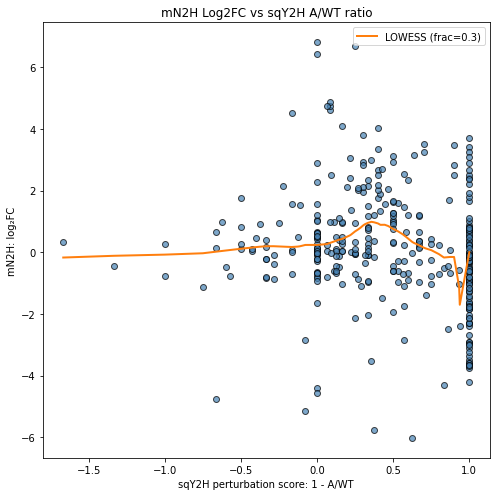

0.20310205317111468

In [84]:
plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    # &
    # (allele_df.WT_detected_pla == True)
    ]

plot_df['1-ratio'] = 1 - plot_df['ratio']

plt.figure(figsize=(7,7))
plt.scatter(
    plot_df['1-ratio'],
    plot_df['log2fc'],
    c='steelblue', alpha=0.7, edgecolor='k'
)

from statsmodels.nonparametric.smoothers_lowess import lowess

frac = 0.3
# frac is the fraction of data used in each local regression (e.g. 0.1 = 10%)
smooth = lowess(
    endog=plot_df['log2fc'],
    exog=plot_df['1-ratio'],
    frac=frac,
    it=3,
    return_sorted=True
)
xs, ys = smooth[:,0], smooth[:,1]

plt.plot(xs, ys, linewidth=2, label=f'LOWESS (frac={frac})', color ='C1')


plt.xlabel('sqY2H perturbation score: 1 - A/WT')
plt.ylabel('mN2H: log₂FC')
plt.title('mN2H Log2FC vs sqY2H A/WT ratio')
plt.legend()
plt.tight_layout()
plt.show()
corr_df = plot_df.dropna(subset=['ratio']).replace([np.inf, -np.inf], np.nan).dropna(subset=['ratio'])
correlation = corr_df['log2fc'].corr(corr_df['ratio'], method='spearman')
correlation


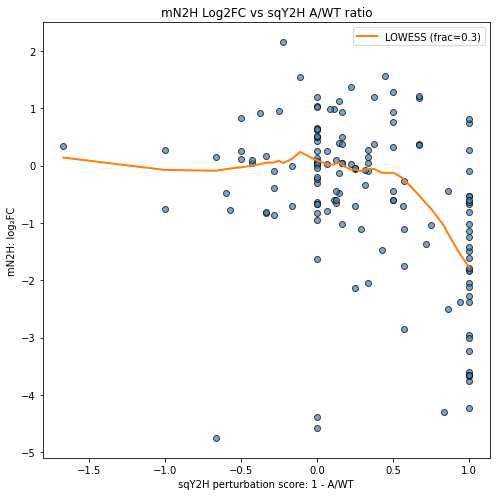

0.3920656436350779

In [85]:
plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    &
    (allele_df.WT_detected_pla == True)
    ]

plot_df['1-ratio'] = 1 - plot_df['ratio']

plt.figure(figsize=(7,7))
plt.scatter(
    plot_df['1-ratio'],
    plot_df['log2fc'],
    c='steelblue', alpha=0.7, edgecolor='k'
)

from statsmodels.nonparametric.smoothers_lowess import lowess

frac = 0.3
# frac is the fraction of data used in each local regression (e.g. 0.1 = 10%)
smooth = lowess(
    endog=plot_df['log2fc'],
    exog=plot_df['1-ratio'],
    frac=frac,
    it=3,
    return_sorted=True
)
xs, ys = smooth[:,0], smooth[:,1]

plt.plot(xs, ys, linewidth=2, label=f'LOWESS (frac={frac})', color ='C1')


plt.xlabel('sqY2H perturbation score: 1 - A/WT')
plt.ylabel('mN2H: log₂FC')
plt.title('mN2H Log2FC vs sqY2H A/WT ratio')
plt.legend()
plt.tight_layout()
plt.show()

corr_df = plot_df.dropna(subset=['ratio']).replace([np.inf, -np.inf], np.nan).dropna(subset=['ratio'])
correlation = corr_df['log2fc'].corr(corr_df['ratio'], method='spearman')
correlation

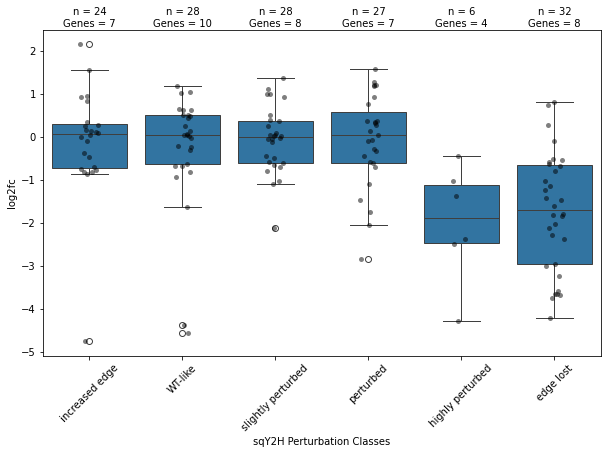

In [86]:
# box and whiskers - perturb 2

plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    &
    (allele_df.WT_detected_pla == True)
    ]

plot_df_perturb = plot_df[plot_df.perturbation_classes_2 == plot_df.perturbation_classes_2]

order = ['increased edge', 'WT-like', 'slightly perturbed', 'perturbed', 'highly perturbed', 'edge lost']


plt.figure(figsize=(10, 6))
sns.boxplot(x='perturbation_classes_2', y='log2fc', data=plot_df_perturb, order=order)
# plt.title('Boxplot of log2fc by perturbation_classes_2')
plt.xlabel('sqY2H Perturbation Classes')
plt.ylabel('log2fc')
plt.xticks(rotation=45)

sns.stripplot(x='perturbation_classes_2', y='log2fc', data=plot_df_perturb, order=order, color='black', alpha=0.5, size=5)

for i, category in enumerate(order):
    count = plot_df_perturb[plot_df_perturb['perturbation_classes_2'] == category].shape[0]
    num_genes = plot_df_perturb[plot_df_perturb['perturbation_classes_2'] == category]['N2_orf_id'].nunique()
    plt.text(i, plt.ylim()[1] * 1.01, f'n = {count}\nGenes = {num_genes}', ha='center', va='bottom')



plt.show()



# Group by perturbation_classes_2 and N2_orf_id, then count unique N2_mut_id values
gene_variant_counts_per_bin = plot_df_perturb.groupby(['perturbation_classes_2', 'N2_orf_id'])['N2_mut_id'].nunique().reset_index()
gene_variant_counts_per_bin.columns = ['Perturbation_Class', 'N2_orf_id', 'Variant_Count']

# for perturbation_class in order:
#     print(f"\nVariants per gene in {perturbation_class} bin:")
#     bin_data = gene_variant_counts_per_bin[gene_variant_counts_per_bin['Perturbation_Class'] == perturbation_class]
#     print(bin_data)


In [87]:
allele_df[(allele_df.N1_orf_id == 6446)

]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,WT_detected_pla,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,fc_class
131,93324.0,6446,ERGIC3,NaN,4062,PLP1,201422,9.0,B01,mN2Hapwtv2,...,True,0.325924,no_perturbation,1,1,0.833333,False,similar,slightly perturbed,Neutral
154,93367.0,6446,ERGIC3,NaN,4062,PLP1,201425,9.0,F06,mN2Hapwtv2,...,True,0.212425,no_perturbation,1,1,NaN,NaN,NaN,NaN,Neutral
157,93371.0,6446,ERGIC3,NaN,4062,PLP1,201426,9.0,B07,mN2Hapwtv2,...,True,-3.615927,decrease_ppi,1,1,0.166667,True,very highly perturbed,highly perturbed,Strong decrease
174,93402.0,6446,ERGIC3,NaN,4062,PLP1,201423,9.0,A11,mN2Hapwtv2,...,True,0.638384,no_perturbation,1,1,0.000000,True,edge lost,edge lost,Neutral
179,93414.0,6446,ERGIC3,NaN,4062,PLP1,201424,9.0,E12,mN2Hapwtv2,...,True,0.054181,no_perturbation,1,1,0.000000,True,edge lost,edge lost,Neutral
192,93430.0,6446,ERGIC3,NaN,4062,PLP1,201428,10.0,F02,mN2Hapwtv2,...,False,-2.107601,decrease_ppi,1,1,0.833333,False,similar,slightly perturbed,Weak increase
201,93453.0,6446,ERGIC3,NaN,4062,PLP1,201427,10.0,E05,mN2Hapwtv2,...,False,-2.397466,decrease_ppi,1,1,0.333333,True,highly perturbed,perturbed,Weak increase
217,93473.0,6446,ERGIC3,NaN,4062,PLP1,201429,10.0,B08,mN2Hapwtv2,...,False,-2.284686,decrease_ppi,1,1,0.666667,False,slightly perturbed,perturbed,Weak increase
223,93487.0,6446,ERGIC3,NaN,4062,PLP1,201430,10.0,H09,mN2Hapwtv2,...,False,-2.744147,decrease_ppi,1,1,0.333333,True,highly perturbed,perturbed,Neutral
229,93498.0,6446,ERGIC3,NaN,4062,PLP1,201431,10.0,C11,mN2Hapwtv2,...,False,-2.396509,decrease_ppi,1,1,1.666667,False,increased edge,increased edge,Weak increase


In [88]:
retest_df[(retest_df.N1_orf_id == 6446)
          &
          (retest_df.variant_id == 'empty_N2')]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,xp_mean,log10fc_empty_N1
751,93350.0,6446.0,ERGIC3,NaN,0.0,NaN,0.0,9.0,E04,mN2Hapwtv2,...,129.0,5784.0,6564.0,8909,False,False,123.0,7085.666667,3604.333333,NaN
841,93440.0,6446.0,ERGIC3,NaN,0.0,NaN,0.0,10.0,H03,mN2Hapwtv2,...,20975.0,41489.0,36104.0,44031,False,False,15410.0,40541.333333,27975.666667,NaN
933,93532.0,6446.0,ERGIC3,NaN,0.0,NaN,0.0,11.0,G03,mN2Hapwtv2,...,1075.0,1854.0,1787.0,2008,False,False,821.0,1883.000000,1352.000000,NaN


In [89]:
retest_df[(retest_df.retest_pla == 10)
          &
          (retest_df.variant_id == 'wt')]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,xp_mean,log10fc_empty_N1
821,93420.0,3731.0,PRPS1,NaN,3731.0,PRPS1,0.0,10.0,D01,mN2Hapwtv2,...,281676.0,388933.0,477480.0,484898,False,False,1.930687e+05,4.504370e+05,3.217528e+05,0.0
826,93425.0,2012.0,LHFPL5,NaN,4062.0,PLP1,0.0,10.0,A02,mN2Hapwtv2,...,1467035.0,1479672.0,1803690.0,1812655,False,False,9.881260e+05,1.698672e+06,1.343399e+06,0.0
844,93443.0,4935.0,SLC18A1,NaN,4062.0,PLP1,0.0,10.0,C04,mN2Hapwtv2,...,1133855.0,1836294.0,1749730.0,1909848,False,False,8.885870e+05,1.831957e+06,1.360272e+06,0.0
845,93444.0,4946.0,PTPRN,NaN,4062.0,PLP1,0.0,10.0,D04,mN2Hapwtv2,...,4523842.0,7228194.0,7457985.0,7669491,False,False,4.969697e+06,7.451890e+06,6.210794e+06,0.0
852,93451.0,11621.0,MTIF3,NaN,4062.0,PLP1,0.0,10.0,C05,mN2Hapwtv2,...,120858.0,237656.0,240057.0,267522,False,False,1.045370e+05,2.484117e+05,1.764743e+05,0.0
875,93474.0,12825.0,CLDN20,NaN,4062.0,PLP1,0.0,10.0,C08,mN2Hapwtv2,...,740256.0,773456.0,733521.0,748005,False,False,4.973887e+05,7.516607e+05,6.245247e+05,0.0
886,93485.0,6446.0,ERGIC3,NaN,4062.0,PLP1,0.0,10.0,F09,mN2Hapwtv2,...,302607.0,415385.0,403393.0,442708,False,False,2.403520e+05,4.204953e+05,3.304237e+05,0.0
895,93494.0,8186.0,CLEC2D,NaN,4062.0,PLP1,0.0,10.0,G10,mN2Hapwtv2,...,1963059.0,3542380.0,3336609.0,3775867,False,False,1.703578e+06,3.551619e+06,2.627598e+06,0.0
900,93499.0,13628.0,KLRC1,NaN,4062.0,PLP1,0.0,10.0,D11,mN2Hapwtv2,...,4187150.0,4625358.0,4786691.0,4147226,False,False,2.793376e+06,4.519758e+06,3.656567e+06,0.0
901,93500.0,5793.0,MS4A3,NaN,4062.0,PLP1,0.0,10.0,E11,mN2Hapwtv2,...,200643.0,233776.0,207441.0,212568,False,False,1.496733e+05,2.179283e+05,1.838008e+05,0.0


In [90]:
retest_df[(retest_df.retest_pla == 10)
          &
          (retest_df.variant_id == 'empty_N2')]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,xp_mean,log10fc_empty_N1
832,93431.0,4946.0,PTPRN,NaN,0.0,NaN,0.0,10.0,G02,mN2Hapwtv2,...,1704249.0,3011019.0,3261079.0,3725548,False,False,1.738708e+06,3.332549e+06,2.535628e+06,NaN
833,93432.0,12825.0,CLDN20,NaN,0.0,NaN,0.0,10.0,H02,mN2Hapwtv2,...,939.0,1854.0,1793.0,1928,False,False,7.386667e+02,1.858333e+03,1.298500e+03,NaN
836,93435.0,11130.0,SLC35E3,NaN,0.0,NaN,0.0,10.0,C03,mN2Hapwtv2,...,619933.0,1346687.0,1127028.0,1190800,False,False,6.393420e+05,1.221505e+06,9.304235e+05,NaN
841,93440.0,6446.0,ERGIC3,NaN,0.0,NaN,0.0,10.0,H03,mN2Hapwtv2,...,20975.0,41489.0,36104.0,44031,False,False,1.541000e+04,4.054133e+04,2.797567e+04,NaN
855,93454.0,8186.0,CLEC2D,NaN,0.0,NaN,0.0,10.0,F05,mN2Hapwtv2,...,24272.0,26900.0,22829.0,30185,False,False,1.642700e+04,2.663800e+04,2.153250e+04,NaN
856,93455.0,5793.0,MS4A3,NaN,0.0,NaN,0.0,10.0,G05,mN2Hapwtv2,...,2118.0,2444.0,2628.0,3064,False,False,1.412000e+03,2.712000e+03,2.062000e+03,NaN
863,93462.0,8165.0,HAS3,NaN,0.0,NaN,0.0,10.0,F06,mN2Hapwtv2,...,19655.0,16849.0,18820.0,18740,False,False,1.357633e+04,1.813633e+04,1.585633e+04,NaN
880,93479.0,3731.0,PRPS1,NaN,0.0,NaN,0.0,10.0,H08,mN2Hapwtv2,...,2622.0,4390.0,5839.0,6005,False,False,1.977000e+03,5.411333e+03,3.694167e+03,NaN
882,93481.0,2012.0,LHFPL5,NaN,0.0,NaN,0.0,10.0,B09,mN2Hapwtv2,...,2462.0,3058.0,3310.0,3217,False,False,1.848000e+03,3.195000e+03,2.521500e+03,NaN
890,93489.0,13628.0,KLRC1,NaN,0.0,NaN,0.0,10.0,B10,mN2Hapwtv2,...,27256.0,30155.0,29897.0,28478,False,False,2.422900e+04,2.951000e+04,2.686950e+04,NaN


13.0


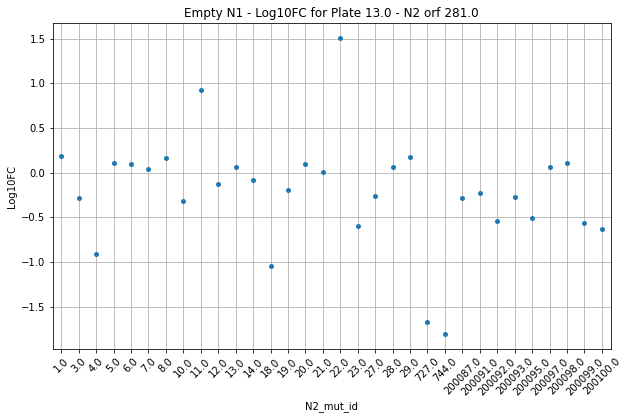

23.0


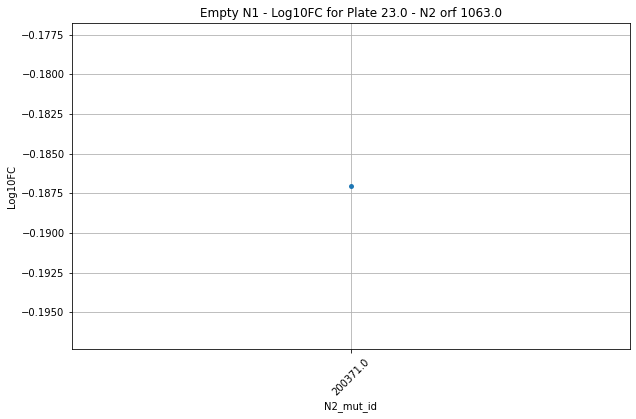

21.0


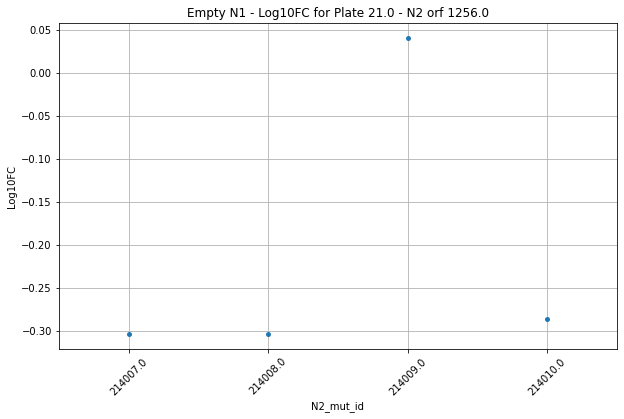

21.0


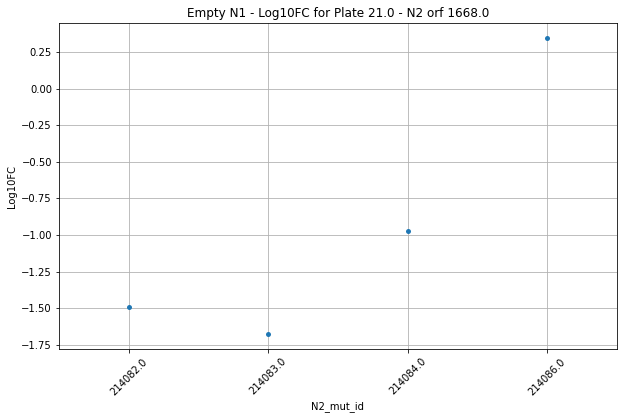

21.0


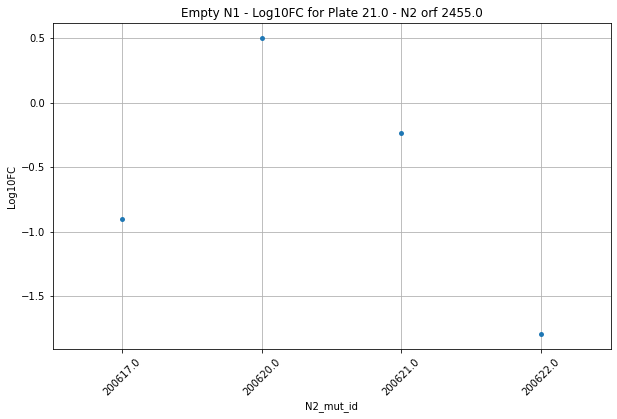

12.0


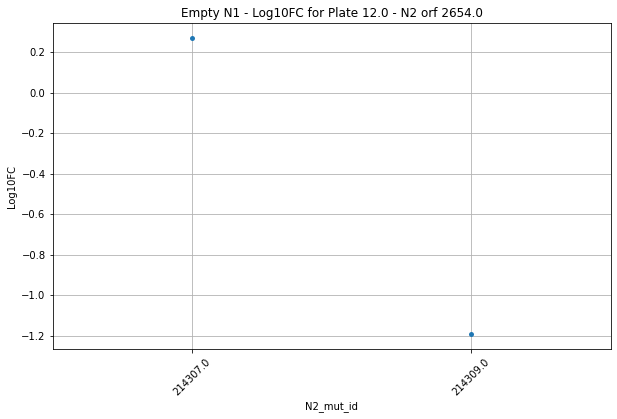

15.0


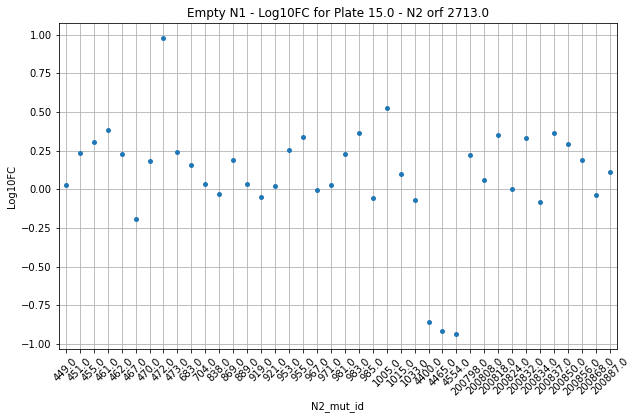

18.0


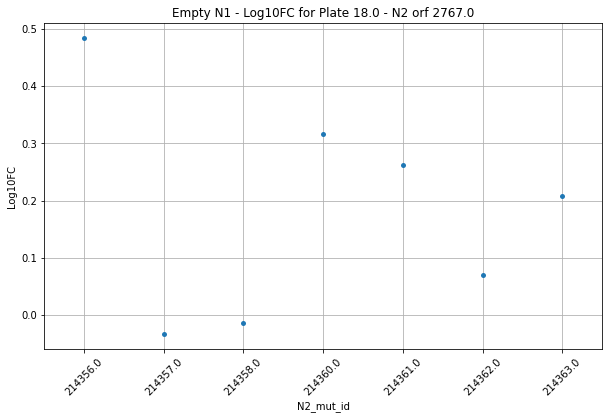

12.0


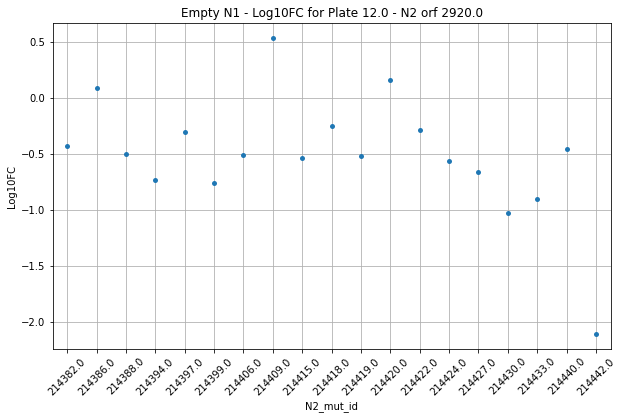

13.0


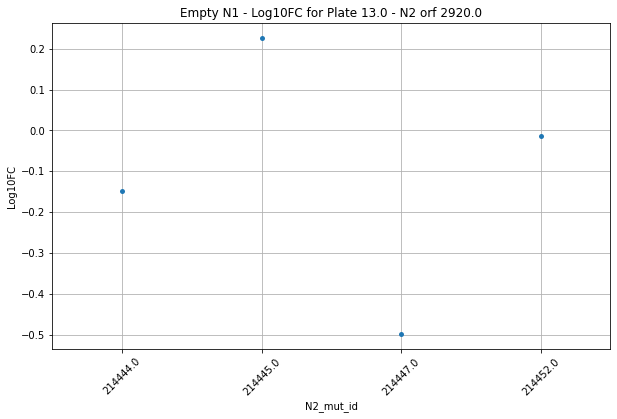

22.0


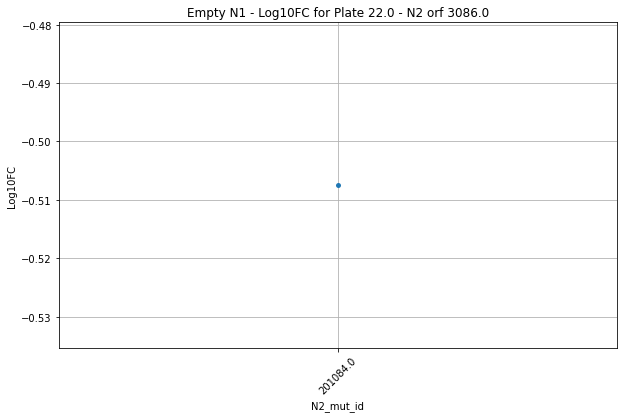

17.0


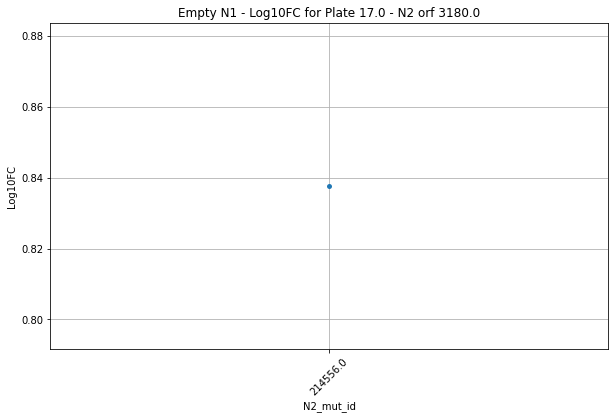

23.0


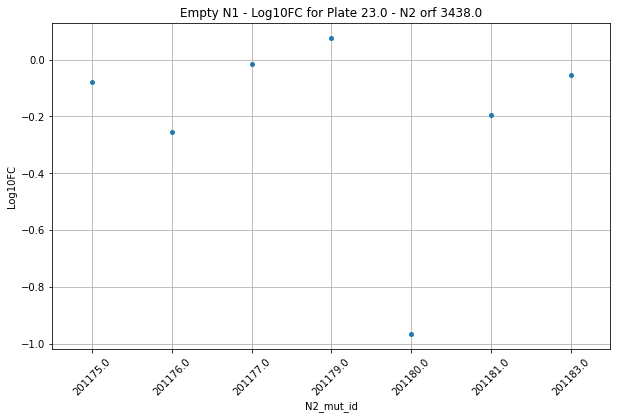

10.0


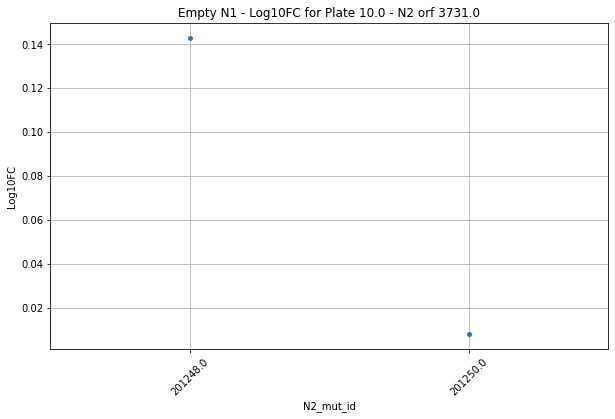

22.0


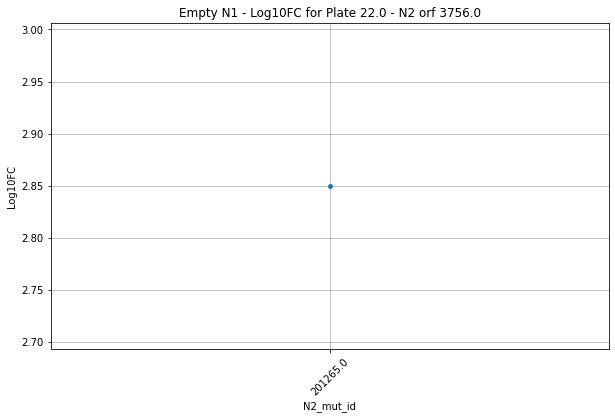

23.0


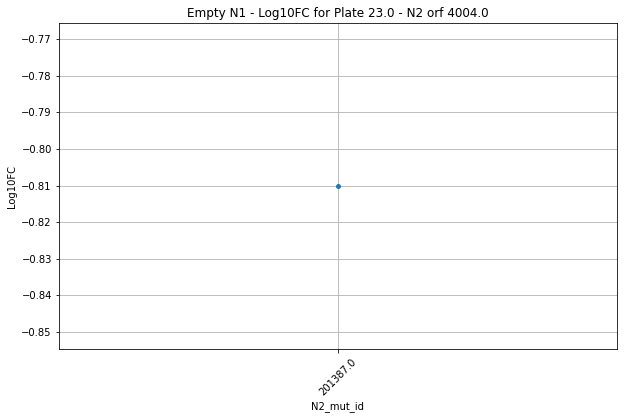

9.0


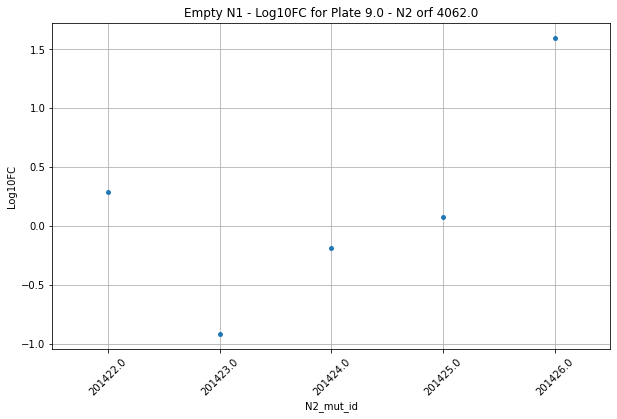

10.0


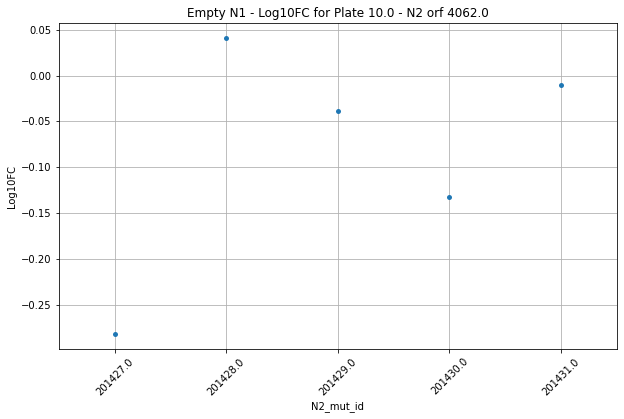

11.0


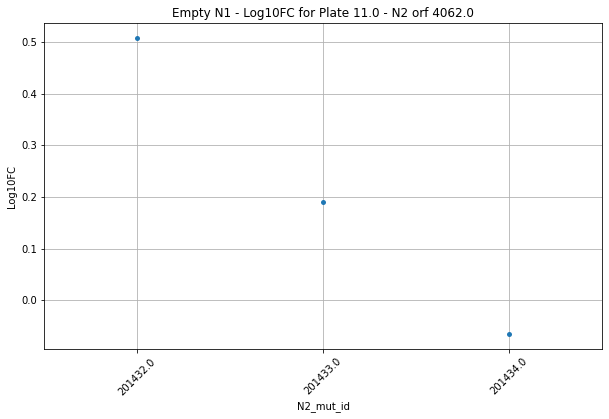

21.0


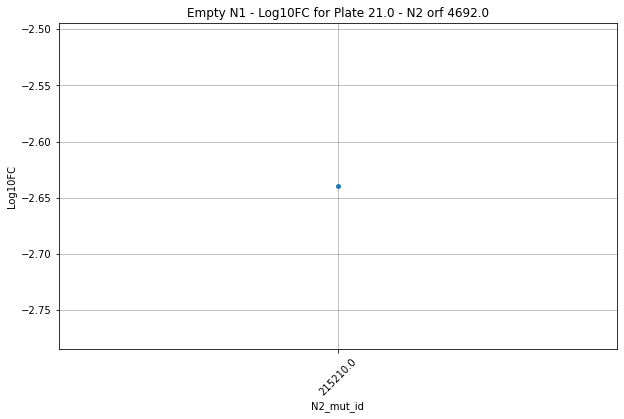

14.0


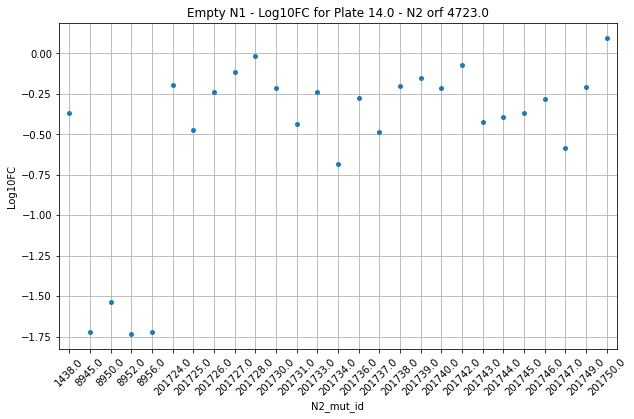

18.0


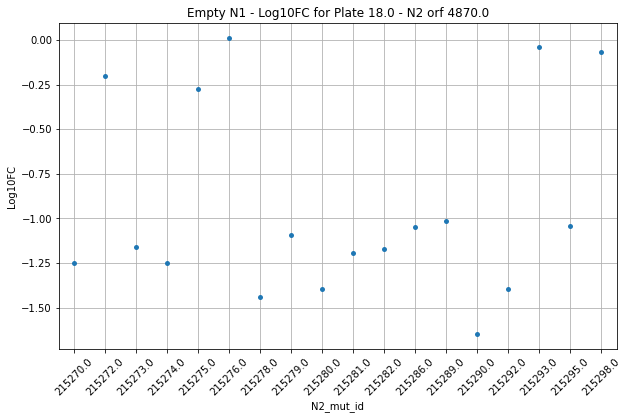

21.0


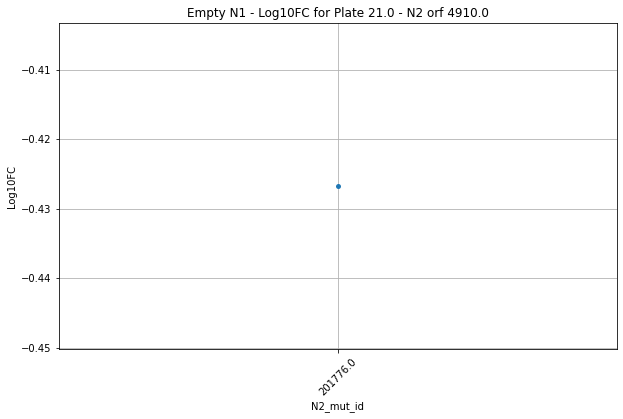

22.0


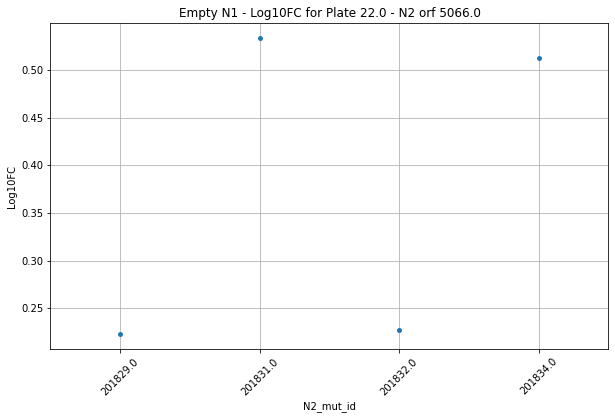

18.0


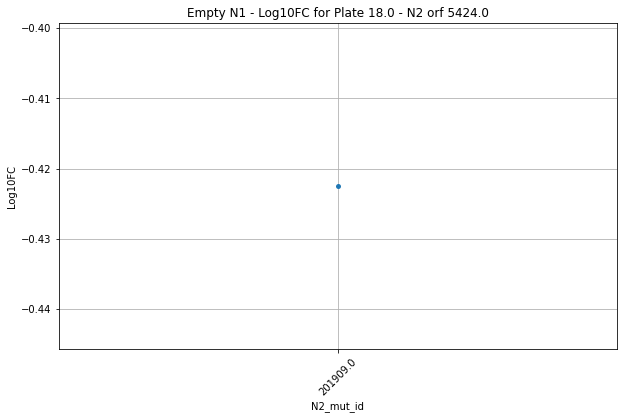

20.0


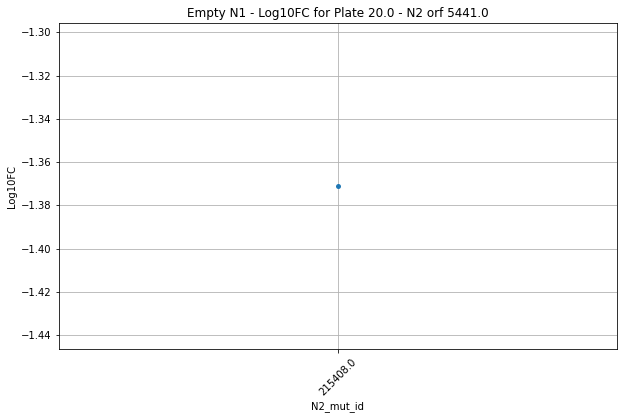

17.0


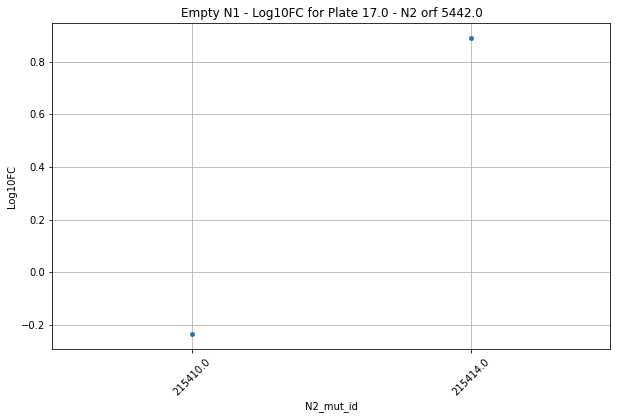

22.0


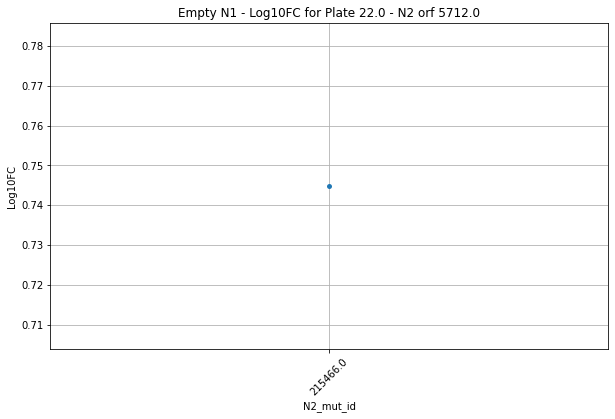

20.0


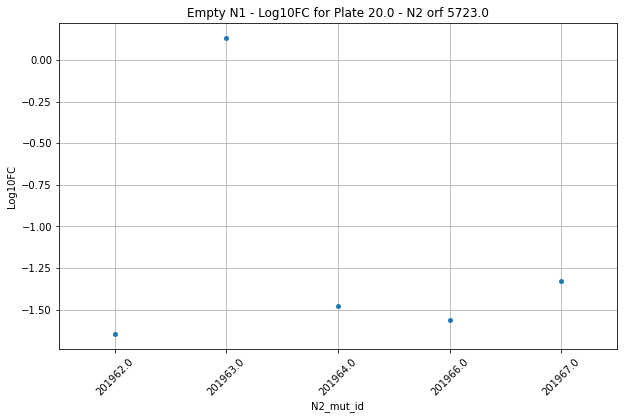

16.0


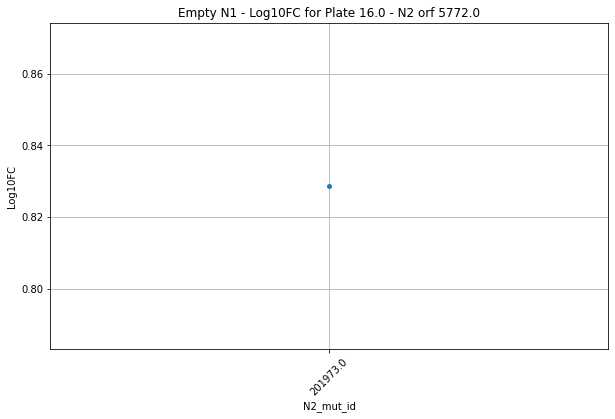

22.0


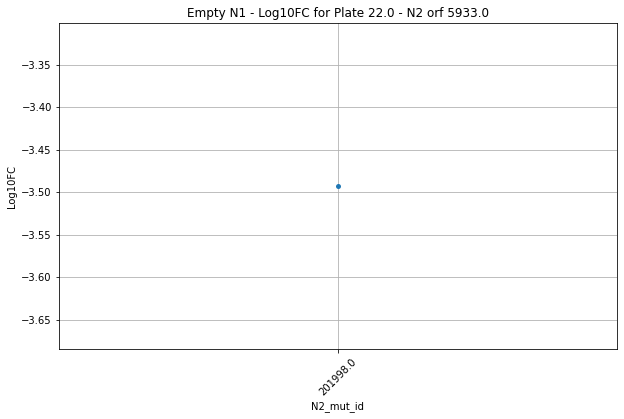

21.0


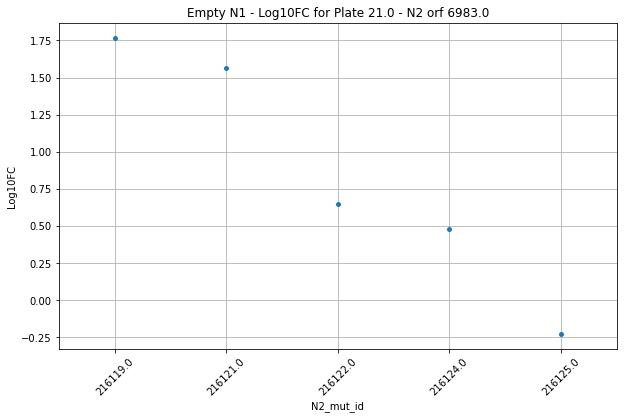

19.0


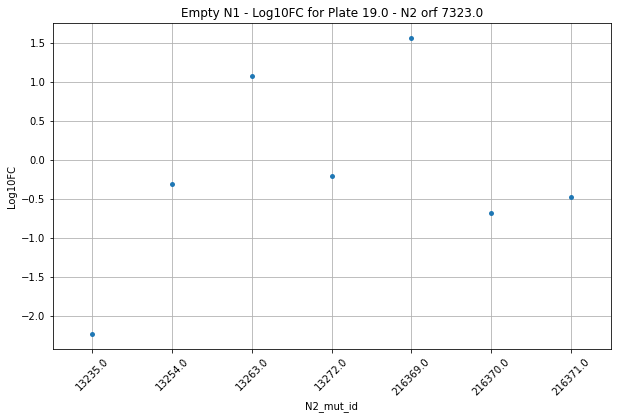

6.0


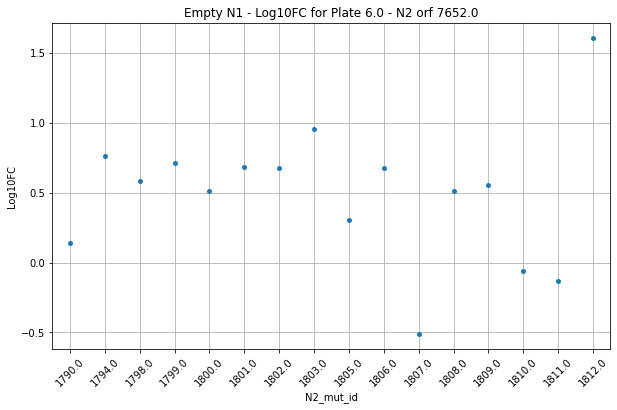

7.0


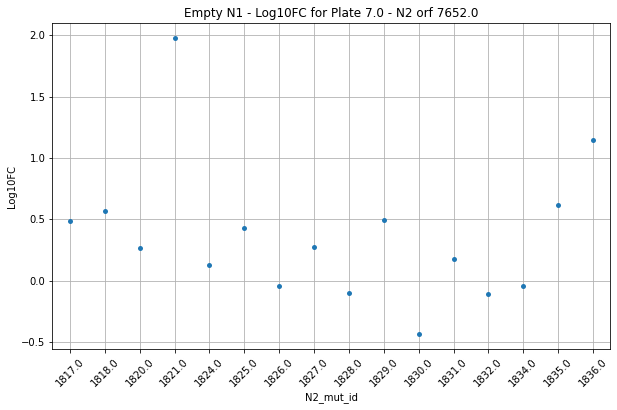

8.0


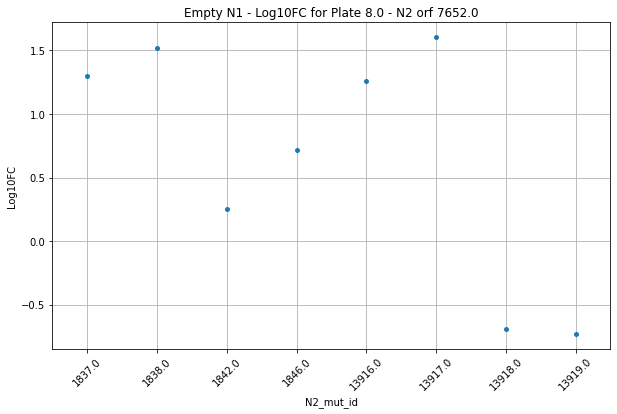

8.0


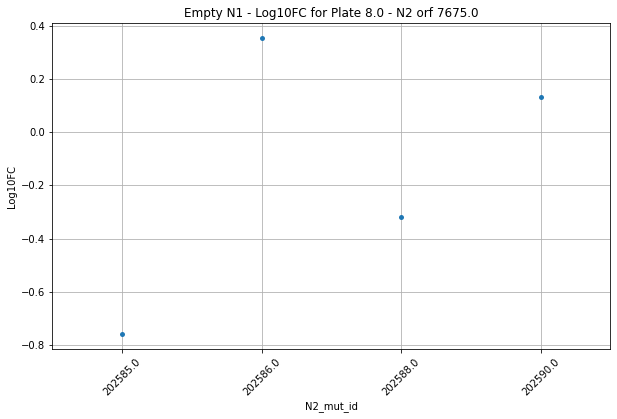

19.0


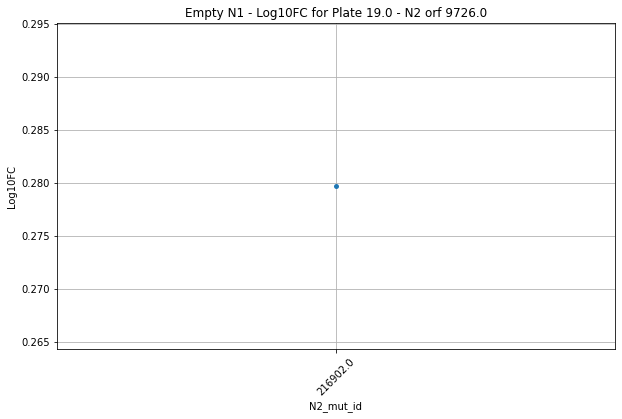

9.0


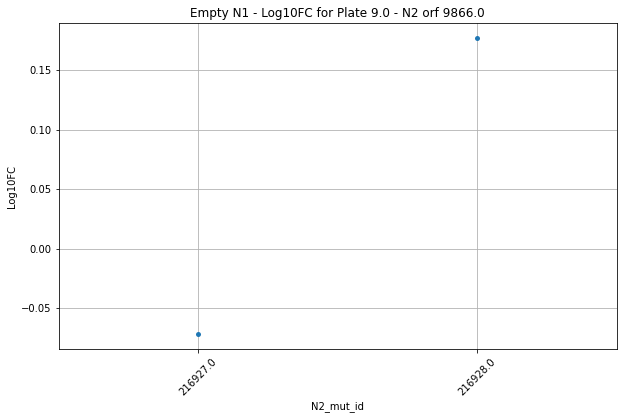

21.0


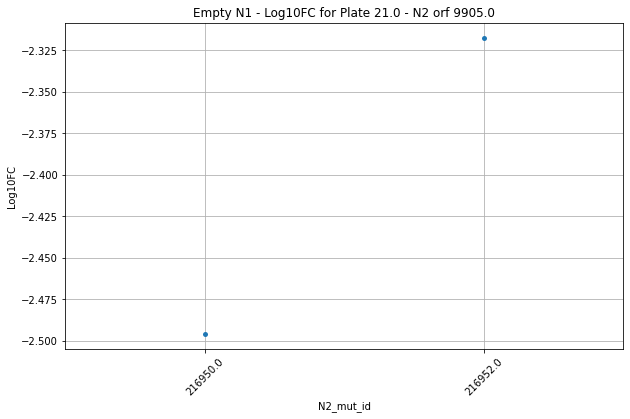

15.0


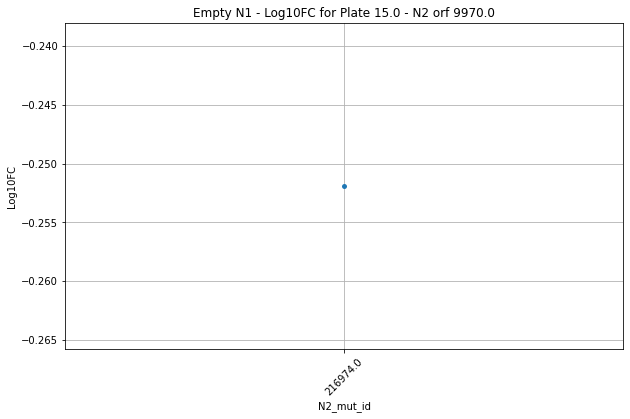

22.0


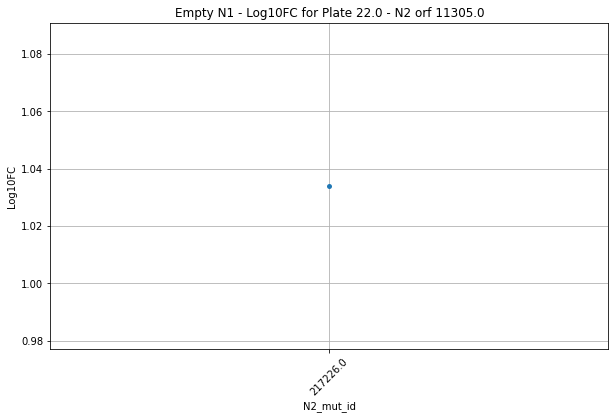

22.0


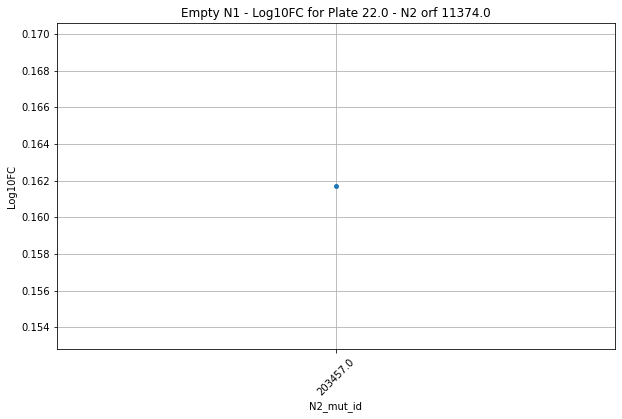

22.0


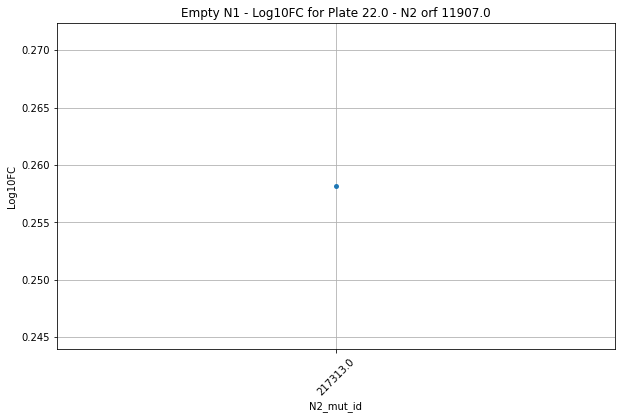

23.0


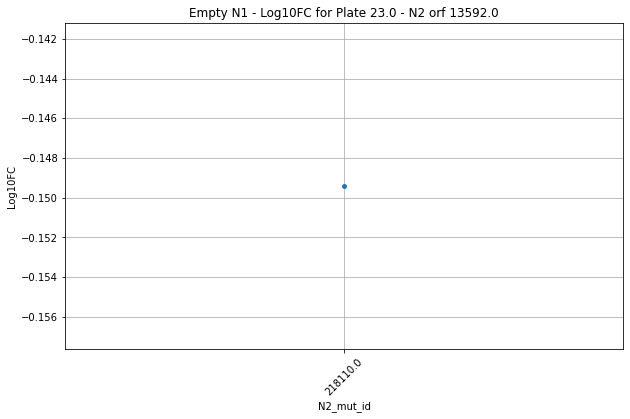

19.0


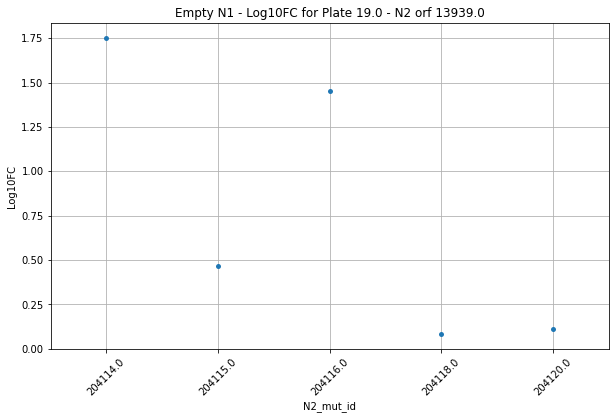

20.0


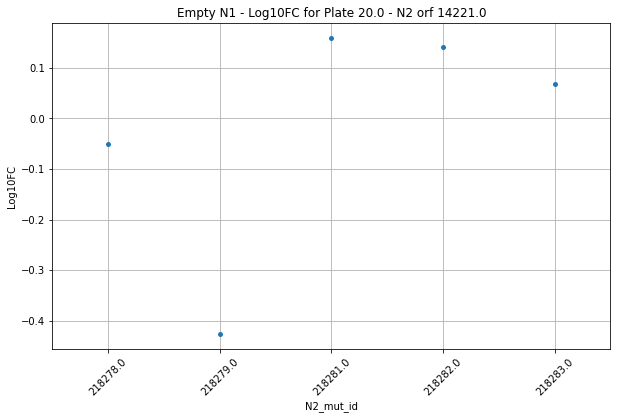

22.0


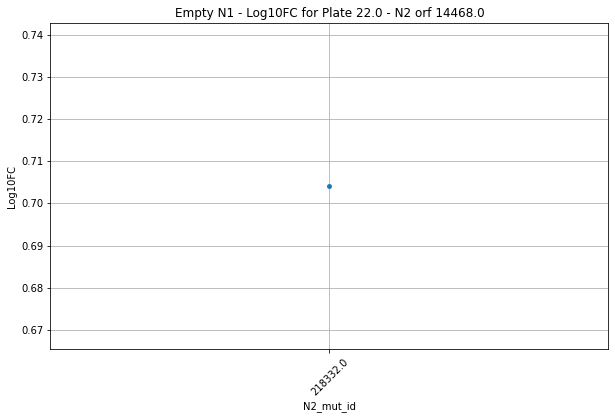

11.0


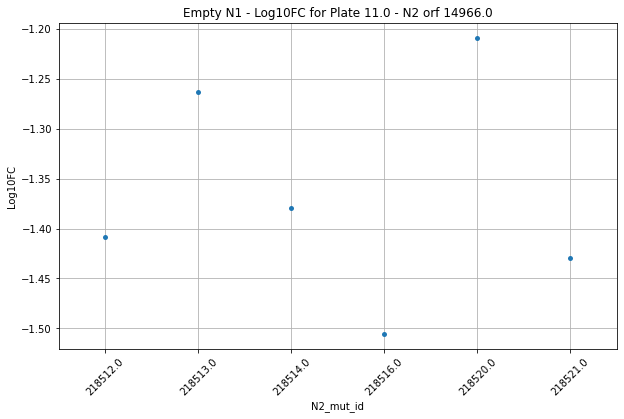

22.0


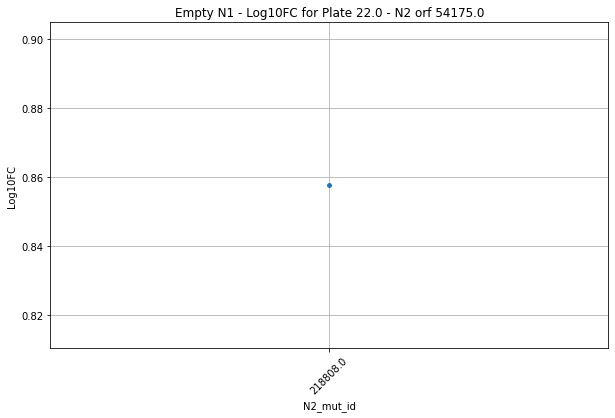

22.0


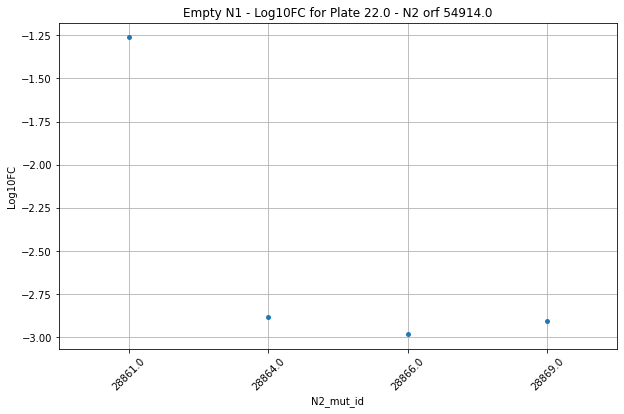

20.0


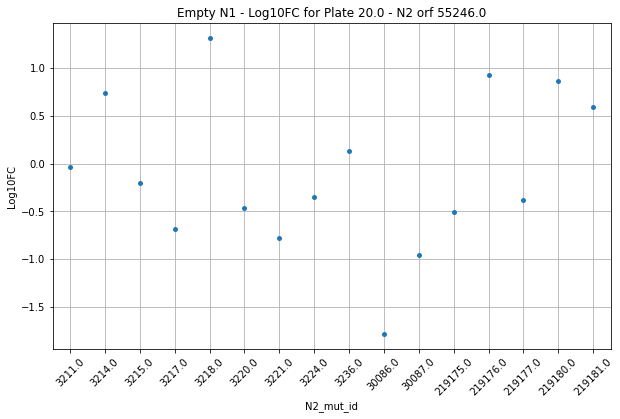

21.0


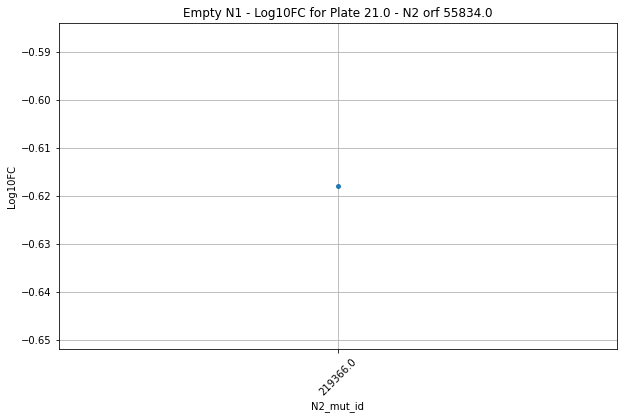

22.0


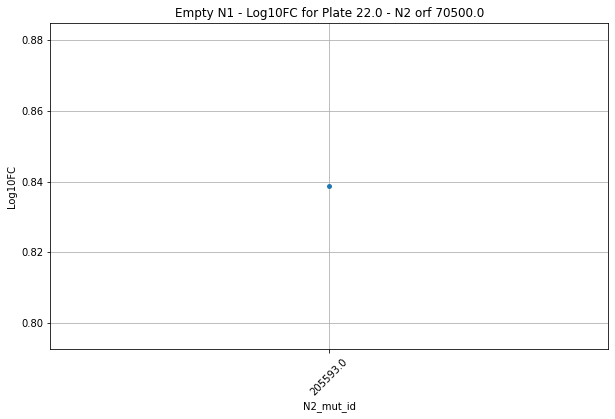

21.0


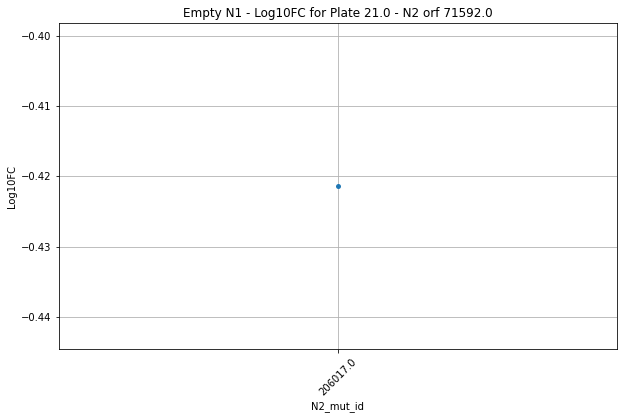

17.0


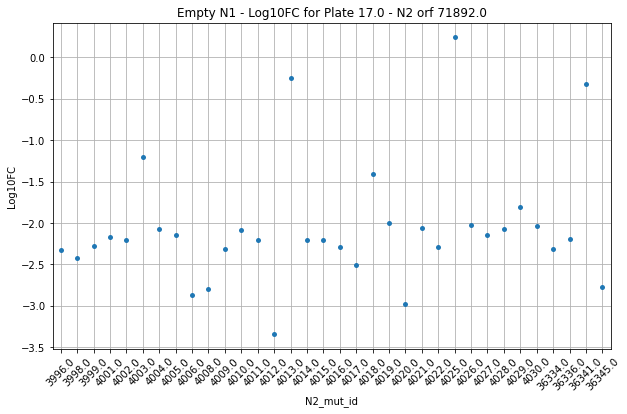

16.0


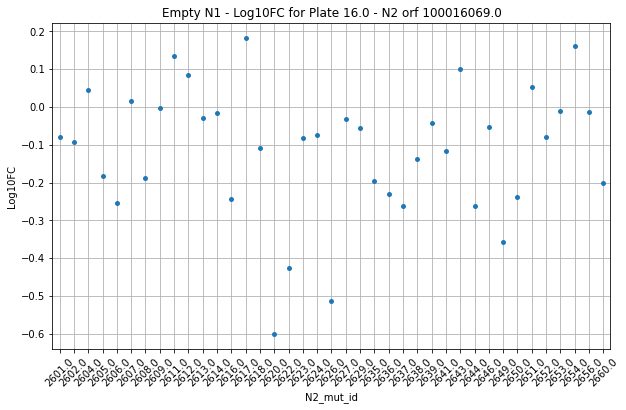

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

for N2_orf_id, df in retest_df[retest_df.variant_id == 'empty_N1'].groupby('N2_orf_id'):
    if N2_orf_id != 0:
    # if N2_orf_id == 4062:
        for pla, df_pla in df.groupby('retest_pla'):
            if pla > 5:
                print(pla)
                wt_xp1 = df_pla[df_pla.N2_mut_id == 0].xp1.values[0]
                alleles_xp1 = df_pla[df_pla.N2_mut_id != 0].xp1.values
                log10fc_values = [np.log10(allele / wt_xp1) for allele in alleles_xp1]

                # Create a DataFrame for plotting
                plot_data = pd.DataFrame({
                    'N2_mut_id': df_pla[df_pla.N2_mut_id != 0].N2_mut_id.values,
                    'log10fc': log10fc_values
                })

                # Plotting
                plt.figure(figsize=(10, 6))
                sns.stripplot(x='N2_mut_id', y='log10fc', data=plot_data, jitter=True)
                plt.title(f'Empty N1 - Log10FC for Plate {pla} - N2 orf {N2_orf_id}')
                plt.xticks(rotation=45)
                plt.xlabel('N2_mut_id')
                plt.ylabel('Log10FC')
                plt.grid(True)
                plt.show()

In [92]:
allele_df[allele_df.perturbation_classes_2 == 'increased edge']

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,WT_detected_pla,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,fc_class
144,93345.0,12825,CLDN20,NaN,4062,PLP1,201422,9.0,H03,mN2Hapwtv2,...,False,-5.737117,decrease_ppi,1,1,1.500000,False,increased edge,increased edge,Moderate increase
152,93364.0,12825,CLDN20,NaN,4062,PLP1,201426,9.0,C06,mN2Hapwtv2,...,False,-5.899594,decrease_ppi,1,1,1.166667,False,increased edge,increased edge,Moderate increase
163,93382.0,4935,SLC18A1,NaN,4062,PLP1,201422,9.0,E08,mN2Hapwtv2,...,False,-4.766295,decrease_ppi,1,1,1.333333,False,increased edge,increased edge,Neutral
170,93390.0,12825,CLDN20,NaN,4062,PLP1,201423,9.0,E09,mN2Hapwtv2,...,False,-7.257428,decrease_ppi,1,1,1.166667,False,increased edge,increased edge,Neutral
186,93422.0,4935,SLC18A1,NaN,4062,PLP1,201428,10.0,F01,mN2Hapwtv2,...,True,0.435971,no_perturbation,1,1,1.333333,False,increased edge,increased edge,Neutral
199,93449.0,12825,CLDN20,NaN,4062,PLP1,201428,10.0,A05,mN2Hapwtv2,...,True,-0.254837,no_perturbation,1,1,1.166667,False,increased edge,increased edge,Weak decrease
202,93456.0,4935,SLC18A1,NaN,4062,PLP1,201431,10.0,H05,mN2Hapwtv2,...,True,0.590166,no_perturbation,1,1,2.666667,False,increased edge,increased edge,Neutral
213,93468.0,13628,KLRC1,NaN,4062,PLP1,201431,10.0,D07,mN2Hapwtv2,...,True,1.020399,no_perturbation,1,1,1.250000,False,increased edge,increased edge,Weak increase
224,93488.0,2012,LHFPL5,NaN,4062,PLP1,201429,10.0,A10,mN2Hapwtv2,...,True,0.026357,no_perturbation,1,1,1.166667,False,increased edge,increased edge,Neutral
226,93493.0,12825,CLDN20,NaN,4062,PLP1,201431,10.0,F10,mN2Hapwtv2,...,True,-0.295138,no_perturbation,1,1,2.000000,False,increased edge,increased edge,Weak decrease


In [126]:
allele_df[allele_df.retest_pla == 8]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,WT_detected_pla,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,fc_class
111,93260.0,7233,STX5,NaN,7652,STXBP1,1837,8.0,B01,mN2Hapwtv2,...,False,2.244421,not_detected,1,1,0.100000,True,very highly perturbed,highly perturbed,Strong increase
112,93261.0,7675,NMNAT1,NaN,7675,NMNAT1,202590,8.0,C01,mN2Hapwtv2,...,True,-1.014141,no_perturbation,1,1,0.714286,False,slightly perturbed,slightly perturbed,Moderate decrease
113,93264.0,7675,NMNAT1,NaN,7675,NMNAT1,202585,8.0,F01,mN2Hapwtv2,...,True,0.575246,no_perturbation,1,1,1.000000,False,WT-like,WT-like,Weak increase
114,93265.0,14387,CENPP,NaN,7652,STXBP1,1838,8.0,G01,mN2Hapwtv2,...,False,0.882189,not_detected,1,1,0.500000,False,perturbed,perturbed,Weak increase
115,93268.0,2615,STX19,NaN,7652,STXBP1,1837,8.0,B02,mN2Hapwtv2,...,False,-0.543154,not_detected,1,1,0.066667,True,very highly perturbed,highly perturbed,Weak decrease
116,93270.0,2615,STX19,NaN,7652,STXBP1,1842,8.0,D02,mN2Hapwtv2,...,False,-0.831306,not_detected,1,1,0.400000,True,highly perturbed,perturbed,Weak decrease
117,93274.0,7675,NMNAT1,NaN,7675,NMNAT1,202586,8.0,H02,mN2Hapwtv2,...,True,-1.497301,no_perturbation,1,1,1.000000,False,WT-like,WT-like,Moderate decrease
118,93277.0,14387,CENPP,NaN,7652,STXBP1,1846,8.0,C03,mN2Hapwtv2,...,False,1.489641,not_detected,1,1,0.000000,True,edge lost,edge lost,Moderate increase
119,93278.0,199,SYTL4,NaN,7652,STXBP1,1838,8.0,D03,mN2Hapwtv2,...,False,2.633404,not_detected,1,1,0.500000,False,perturbed,perturbed,Strong increase
120,93288.0,14387,CENPP,NaN,7652,STXBP1,1837,8.0,F04,mN2Hapwtv2,...,False,0.153303,not_detected,1,1,0.000000,True,edge lost,edge lost,Neutral


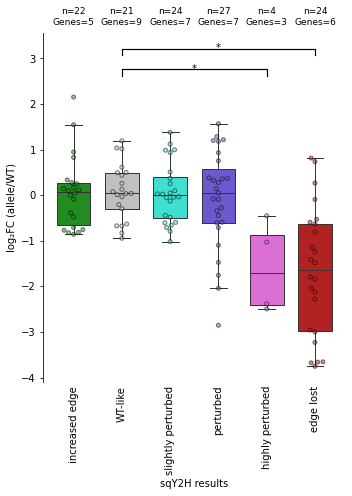

In [128]:


from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
    'increased edge',
    'WT-like',
    'slightly perturbed',
    'perturbed',
    'highly perturbed',
    'edge lost'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
    'firebrick'   # gray
]

palette = dict(zip(order, box_colors))


plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    &
    (allele_df.WT_detected_pla == True)
    &
    (allele_df.log10fc_empty_N1.between(-1,1))
    &
    (allele_df.retest_pla != 8)
    &
    (allele_df.retest_pla != 9)
    ]

plot_df_perturb = plot_df[plot_df.perturbation_classes_2 == plot_df.perturbation_classes_2]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.70, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H results')
ax.set_ylabel('log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in pairs:
    x = df_plot.loc[df_plot.perturbation_classes_2==g1, 'log2fc']
    y = df_plot.loc[df_plot.perturbation_classes_2==g2, 'log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['log2fc'].max()
y_min = df_plot['log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbation_classes_2 == cat]
    n_edges = len(sub)
    n_genes = sub['N2_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)

plt.tight_layout()
plt.show()


In [130]:
allele_df[(allele_df.perturbation_classes_2 == 'perturbed')&
          (allele_df.WT_detected == True)]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,WT_detected_pla,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,fc_class
134,93330.0,4935,SLC18A1,NaN,4062,PLP1,201426,9.0,A02,mN2Hapwtv2,...,False,-4.408717,decrease_ppi,1,1,0.333333,True,highly perturbed,perturbed,Neutral
141,93338.0,8186,CLEC2D,NaN,4062,PLP1,201422,9.0,A03,mN2Hapwtv2,...,False,-4.171867,decrease_ppi,1,1,0.333333,True,highly perturbed,perturbed,Weak increase
146,93352.0,11130,SLC35E3,NaN,4062,PLP1,201422,9.0,G04,mN2Hapwtv2,...,False,-1.314350,no_perturbation,1,1,0.500000,False,perturbed,perturbed,Neutral
168,93388.0,4935,SLC18A1,NaN,4062,PLP1,201423,9.0,C09,mN2Hapwtv2,...,False,-5.441616,decrease_ppi,1,1,0.666667,False,slightly perturbed,perturbed,Weak decrease
171,93391.0,2012,LHFPL5,NaN,4062,PLP1,201422,9.0,F09,mN2Hapwtv2,...,False,-6.961057,decrease_ppi,1,1,0.500000,False,perturbed,perturbed,Moderate increase
180,93415.0,11130,SLC35E3,NaN,4062,PLP1,201423,9.0,F12,mN2Hapwtv2,...,False,-3.361528,decrease_ppi,1,1,0.500000,False,perturbed,perturbed,Moderate decrease
182,93417.0,4935,SLC18A1,NaN,4062,PLP1,201427,10.0,A01,mN2Hapwtv2,...,True,0.631533,no_perturbation,1,1,0.333333,True,highly perturbed,perturbed,Neutral
191,93429.0,13628,KLRC1,NaN,4062,PLP1,201430,10.0,E02,mN2Hapwtv2,...,True,0.499042,no_perturbation,1,1,0.625000,False,slightly perturbed,perturbed,Neutral
193,93434.0,4946,PTPRN,NaN,4062,PLP1,201429,10.0,B03,mN2Hapwtv2,...,False,-5.089786,decrease_ppi,1,1,0.375000,True,highly perturbed,perturbed,Neutral
197,93447.0,4935,SLC18A1,NaN,4062,PLP1,201430,10.0,G04,mN2Hapwtv2,...,True,0.541610,no_perturbation,1,1,0.666667,False,slightly perturbed,perturbed,Neutral


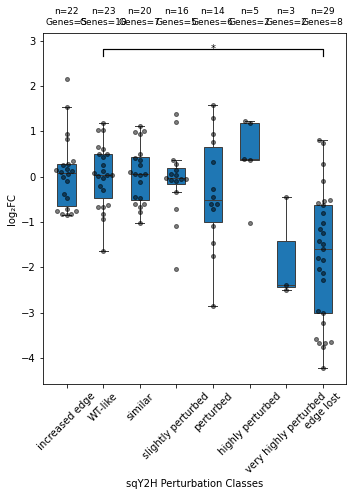

In [94]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
    'increased edge',
    'WT-like',
    'similar',
    'slightly perturbed',
    'perturbed',
    'highly perturbed',
    'very highly perturbed',
    'edge lost'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
    'firebrick'   # gray
]

palette = dict(zip(order, box_colors))


plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    &
    (allele_df.WT_detected_pla == True)
    &
    (allele_df.log10fc_empty_N1.between(-1,1))
    ]

plot_df_perturb = plot_df[plot_df.perturbation_classes == plot_df.perturbation_classes]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbation_classes', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.5,  saturation=1
)
sns.swarmplot(
    x='perturbation_classes', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1
)

ax.set_xlabel('sqY2H Perturbation Classes')
ax.set_ylabel('log₂FC')
ax.tick_params(axis='x', rotation=45)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in pairs:
    x = df_plot.loc[df_plot.perturbation_classes==g1, 'log2fc']
    y = df_plot.loc[df_plot.perturbation_classes==g2, 'log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['log2fc'].max()
y_min = df_plot['log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbation_classes == cat]
    n_edges = len(sub)
    n_genes = sub['N2_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )


plt.tight_layout()
plt.show()


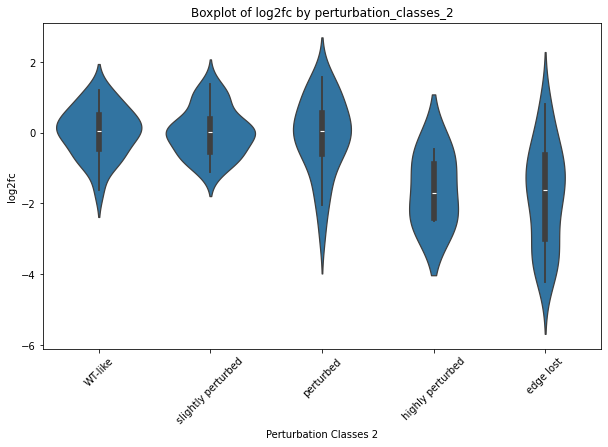

In [95]:
# volcano plot


plot_df_perturb = plot_df[plot_df.perturbation_classes_2 == plot_df.perturbation_classes_2]

order = ['WT-like', 'slightly perturbed', 'perturbed', 'highly perturbed', 'edge lost']


plt.figure(figsize=(10, 6))
sns.violinplot(x='perturbation_classes_2', y='log2fc', data=plot_df_perturb, order=order)
plt.title('Boxplot of log2fc by perturbation_classes_2')
plt.xlabel('Perturbation Classes 2')
plt.ylabel('log2fc')
plt.xticks(rotation=45)
plt.show()


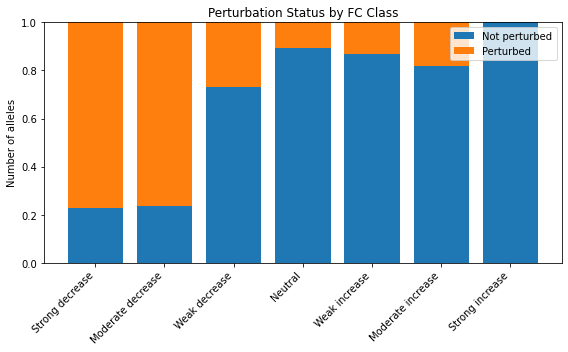

In [96]:
import matplotlib.pyplot as plt

plot_df = allele_df[
    (allele_df.repeat_zscore == False) 
    &
    (allele_df.WT_detected_pla == True)
                    ]

# 1) Tabulate counts of perturbed vs. not per class
counts = plot_df.groupby(['fc_class', 'perturbed']) \
                  .size() \
                  .unstack(fill_value=0)

# 2) (Optional) Enforce a biologically meaningful order
order = [
    'Strong decrease',
    'Moderate decrease',
    'Weak decrease',
    'Neutral',
    'Weak increase',
    'Moderate increase',
    'Strong increase'
]
counts = counts.reindex(order).fillna(0)

props = counts.div(counts.sum(axis=1), axis=0)

# 3) Build the stacked bar chart
plt.figure(figsize=(8, 5))
x = range(len(props))
not_pert = props[False].values
pert     = props[True].values

plt.bar(x, not_pert, label='Not perturbed')
plt.bar(x, pert, bottom=not_pert, label='Perturbed')

plt.xticks(x, props.index, rotation=45, ha='right')
plt.ylabel('Number of alleles')
plt.title('Perturbation Status by FC Class')
plt.legend()
plt.tight_layout()
plt.show()

# Final figure

In [97]:
#wtpwt_normalized_df = pd.read_csv(f'{outputs_dir}/mN2H_wtpwt_allele_df.csv')
apwt_normalized_df = pd.read_csv(f'{outputs_dir}/mN2H_apwt_allele_df.csv')

keep_cols = ["variant_id", "avg_NLR", "repeat_zscore", "ppi_perturbation_class_04"]

## Pertubed vs not-perturbed

33.83678230982681


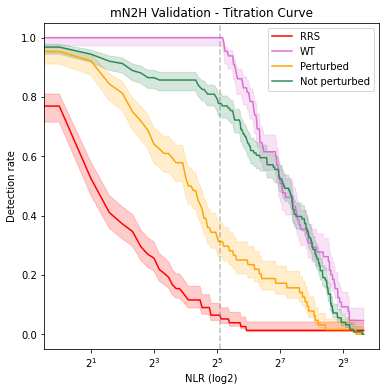

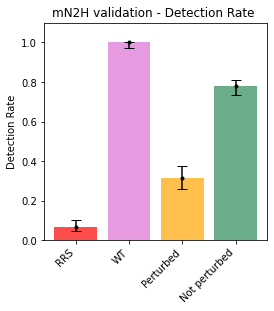

[0.0641025641025641, 1.0, 0.3125, 0.7777777777777778]

In [98]:
# BINARY PPI PERTURBATION CLASS


#limited to WT positive pairs
rrs_mean = np.mean(normalized_df[(normalized_df.variant_id == 'RRS')&(normalized_df.avg_NLR < 200)].avg_NLR)
rrs_std = np.std(normalized_df[(normalized_df.variant_id == 'RRS')&(normalized_df.avg_NLR < 200)].avg_NLR)

threshold = 2.326*rrs_std+rrs_mean
print(threshold)


positive_wt_pairs = set(normalized_df[(normalized_df.variant_id == 'wt')&(normalized_df.avg_NLR >= threshold)].pair)
    

res_d = {}

for i in range(-8,800):
    trsh = i
    
    rrs_pos, rrs_neg = (normalized_df[(normalized_df.variant_id == 'RRS')].avg_NLR >= trsh).sum(), (normalized_df[(normalized_df.variant_id == 'RRS')].avg_NLR < trsh).sum()
    rrs_lower, rrs_upper = stats.beta.interval(0.6827, rrs_pos + 1, rrs_neg + 1)
    rrs_rate = rrs_pos/(rrs_pos+rrs_neg)
    
    wt_pos = (normalized_df[(normalized_df.variant_id == 'wt')&
                            (normalized_df.pair.isin(positive_wt_pairs))&
                            (normalized_df.avg_NLR >= threshold)&
                            (normalized_df.repeat_zscore == False)
                            ].avg_NLR >= trsh).sum()

    wt_neg = (normalized_df[(normalized_df.variant_id == 'wt')&
                            (normalized_df.pair.isin(positive_wt_pairs))&
                            (normalized_df.avg_NLR >= threshold)&
                            (normalized_df.repeat_zscore == False)].avg_NLR < trsh).sum()

    wt_lower, wt_upper = stats.beta.interval(0.6827, wt_pos + 1, wt_neg + 1)
    wt_rate = wt_pos/(wt_pos+wt_neg)
    res_d[i] = {'trsh':trsh,'rrs_rate':rrs_rate, 'rrs_lower':rrs_lower, 'rrs_upper':rrs_upper,'wt_rate':wt_rate, 'wt_lower':wt_lower, 'wt_upper':wt_upper}
    
    for cat in [True, False]:
      pos = ((allele_df.perturbed == cat)&
             (allele_df.avg_NLR >= trsh)&
               (allele_df.pair.isin(positive_wt_pairs))&
              # (allele_df.WT_detected == True)&
               (allele_df.repeat_zscore == False)).sum()
      neg = ((allele_df.perturbed == cat)&
             (allele_df.avg_NLR < trsh)&
               (allele_df.pair.isin(positive_wt_pairs))&
            #   (allele_df.WT_detected == True)&
               (allele_df.repeat_zscore == False)).sum()
      lower, upper = stats.beta.interval(0.6827, pos + 1, neg + 1)
      rate = pos/(pos+neg)
      res_d[i][f'{cat}_rate'] = rate
      res_d[i][f'{cat}_lower'] = lower
      res_d[i][f'{cat}_upper'] = upper

rate_df = pd.DataFrame(res_d).T

plt.figure(figsize=(6,6))
plt.title('mN2H Validation - Titration Curve')
cats = ['rrs','wt', 'True', 'False']
cat_d = dict(zip(cats,['RRS','WT', 'Perturbed', 'Not perturbed']))
colors = ['r','orchid','orange','seagreen']

for cat,color in zip(cats,colors):

    ax = sns.lineplot(data=rate_df, x='trsh' , y=f'{cat}_rate', color=color, label=cat_d[cat])
    ax.fill_between(rate_df.trsh, rate_df[f'{cat}_upper'], rate_df[f'{cat}_lower'], alpha=0.2, color=color)

plt.axvline(x=threshold, color='grey', linestyle='--', alpha=0.5)

#plt.xlim((0,7))
plt.ylim((-0.05,1.05))
plt.xlabel('NLR (log2)')
plt.ylabel('Detection rate')
plt.xscale('log', base=2)
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_titration_curve.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_titration_curve.png', dpi=300,  bbox_inches='tight')
plt.show()

plt.figure(figsize=(4,4))
plt.title('mN2H validation - Detection Rate ')
lower_error = [abs(res_d[int(threshold)][f'{cat}_rate'] - res_d[int(threshold)][f'{cat}_lower'])  for cat in cats]
upper_error = [abs(res_d[int(threshold)][f'{cat}_rate'] - res_d[int(threshold)][f'{cat}_upper'])  for cat in cats]
asymmetric_error = np.array(list(zip(lower_error, upper_error))).T

x = cat_d.values()
y = [e[1] for e in res_d[int(threshold)].items() if 'rate' in e[0]]

plt.bar(x, y, color = colors,alpha=0.7)  #color=['black', 'red', 'green', 'blue', 'cyan']
plt.errorbar(x, y, yerr=asymmetric_error, fmt='.', color = 'black',ecolor = 'black', capsize=5)
plt.ylim((0,1.1))
plt.ylabel('Detection Rate')
plt.xticks(rotation = 45, ha='right')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_detection_rate.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_detection_rate.png', dpi=300,  bbox_inches='tight')
plt.show()
y

## Perturbed classes

33.83678230982681


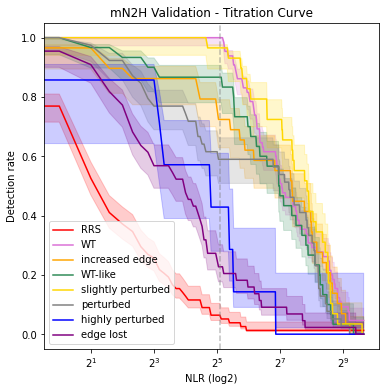

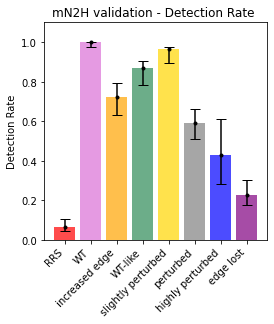

In [99]:
## plot detection rate for different thresholds

#limited to WT positive pairs
rrs_mean = np.mean(normalized_df[(normalized_df.variant_id == 'RRS')&(normalized_df.avg_NLR < 200)].avg_NLR)
rrs_std = np.std(normalized_df[(normalized_df.variant_id == 'RRS')&(normalized_df.avg_NLR < 200)].avg_NLR)

threshold = 2.326*rrs_std+rrs_mean
print(threshold)

positive_wt_pairs = set(normalized_df[(normalized_df.variant_id == 'wt')&(normalized_df.avg_NLR >= threshold )].pair)

res_d = {}

for i in range(-8,800):
    trsh = i
    
    rrs_pos, rrs_neg = (normalized_df[(normalized_df.variant_id == 'RRS')].avg_NLR >= trsh).sum(), (normalized_df[(normalized_df.variant_id == 'RRS')].avg_NLR < trsh).sum()
    rrs_lower, rrs_upper = stats.beta.interval(0.6827, rrs_pos + 1, rrs_neg + 1)
    rrs_rate = rrs_pos/(rrs_pos+rrs_neg)
    
    wt_pos = (normalized_df[(normalized_df.variant_id == 'wt')&
                            (normalized_df.pair.isin(positive_wt_pairs))&
                            (normalized_df.avg_NLR >= threshold)&
                            (normalized_df.repeat_zscore == False)
                            ].avg_NLR >= trsh).sum()

    wt_neg = (normalized_df[(normalized_df.variant_id == 'wt')&
                            (normalized_df.pair.isin(positive_wt_pairs))&
                            (normalized_df.avg_NLR >= threshold)&
                            (normalized_df.repeat_zscore == False)].avg_NLR < trsh).sum()

    wt_lower, wt_upper = stats.beta.interval(0.6827, wt_pos + 1, wt_neg + 1)
    wt_rate = wt_pos/(wt_pos+wt_neg)
    res_d[i] = {'trsh':trsh,'rrs_rate':rrs_rate, 'rrs_lower':rrs_lower, 'rrs_upper':rrs_upper,'wt_rate':wt_rate, 'wt_lower':wt_lower, 'wt_upper':wt_upper}
    
    for cat in ["increased edge",
                'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]:
      pos = ((allele_df.perturbation_classes_2 == cat)&
             (allele_df.avg_NLR >= trsh)&
               (allele_df.pair.isin(positive_wt_pairs))&
               (allele_df.repeat_zscore == False)).sum()
      neg = ((allele_df.perturbation_classes_2 == cat)&
             (allele_df.avg_NLR < trsh)&
               (allele_df.pair.isin(positive_wt_pairs))&
               (allele_df.repeat_zscore == False)).sum()
      lower, upper = stats.beta.interval(0.6827, pos + 1, neg + 1)
      rate = pos/(pos+neg)
      res_d[i][f'{cat}_rate'] = rate
      res_d[i][f'{cat}_lower'] = lower
      res_d[i][f'{cat}_upper'] = upper

rate_df = pd.DataFrame(res_d).T

plt.figure(figsize=(6,6))
plt.title('mN2H Validation - Titration Curve')
cats = ['rrs','wt', "increased edge",
        'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]
cat_d = dict(zip(cats,['RRS','WT',"increased edge",
                       'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]))
colors = ['r','orchid','orange','seagreen','gold','gray','b','purple','k','g']

for cat,color in zip(cats,colors):

    ax = sns.lineplot(data=rate_df, x='trsh' , y=f'{cat}_rate', color=color, label=cat_d[cat])
    ax.fill_between(rate_df.trsh, rate_df[f'{cat}_upper'], rate_df[f'{cat}_lower'], alpha=0.2, color=color)

plt.axvline(x=threshold, color='grey', linestyle='--', alpha=0.5)

#plt.xlim((0,7))
plt.ylim((-0.05,1.05))
plt.xlabel('NLR (log2)')
plt.ylabel('Detection rate')
plt.xscale('log', base=2)
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_titration_curve.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_titration_curve.png', dpi=300,  bbox_inches='tight')
plt.show()

plt.figure(figsize=(4,4))
plt.title('mN2H validation - Detection Rate ')
lower_error = [abs(res_d[int(threshold)][f'{cat}_rate'] - res_d[int(threshold)][f'{cat}_lower'])  for cat in cats]
upper_error = [abs(res_d[int(threshold)][f'{cat}_rate'] - res_d[int(threshold)][f'{cat}_upper'])  for cat in cats]
asymmetric_error = np.array(list(zip(lower_error, upper_error))).T

x = cat_d.values()
y = [e[1] for e in res_d[int(threshold)].items() if 'rate' in e[0]]

plt.bar(x, y, color = colors,alpha=0.7)  #color=['black', 'red', 'green', 'blue', 'cyan']
plt.errorbar(x, y, yerr=asymmetric_error, fmt='.', color = 'black',ecolor = 'black', capsize=5)
plt.ylim((0,1.1))
plt.ylabel('Detection Rate')
plt.xticks(rotation = 45, ha='right')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_detection_rate.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_detection_rate.png', dpi=300,  bbox_inches='tight')
plt.show()

33.83678230982681


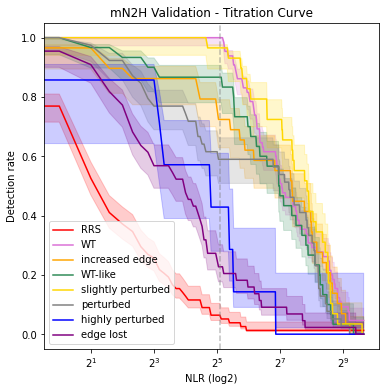

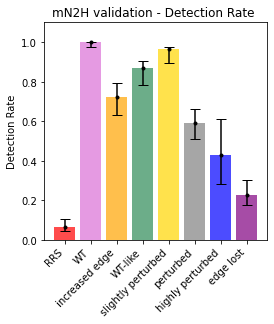

In [100]:
## plot detection rate for different thresholds

#limited to WT positive pairs
rrs_mean = np.mean(normalized_df[(normalized_df.variant_id == 'RRS')&(normalized_df.avg_NLR < 200)].avg_NLR)
rrs_std = np.std(normalized_df[(normalized_df.variant_id == 'RRS')&(normalized_df.avg_NLR < 200)].avg_NLR)

threshold = 2.326*rrs_std+rrs_mean
print(threshold)

positive_wt_pairs = set(normalized_df[(normalized_df.variant_id == 'wt')&(normalized_df.avg_NLR >= threshold )].pair)

res_d = {}

for i in range(-8,800):
    trsh = i
    
    rrs_pos, rrs_neg = (normalized_df[(normalized_df.variant_id == 'RRS')].avg_NLR >= trsh).sum(), (normalized_df[(normalized_df.variant_id == 'RRS')].avg_NLR < trsh).sum()
    rrs_lower, rrs_upper = stats.beta.interval(0.6827, rrs_pos + 1, rrs_neg + 1)
    rrs_rate = rrs_pos/(rrs_pos+rrs_neg)
    
    wt_pos = (normalized_df[(normalized_df.variant_id == 'wt')&
                            (normalized_df.pair.isin(positive_wt_pairs))&
                            (normalized_df.avg_NLR >= threshold)&
                            (normalized_df.repeat_zscore == False)
                            ].avg_NLR >= trsh).sum()

    wt_neg = (normalized_df[(normalized_df.variant_id == 'wt')&
                            (normalized_df.pair.isin(positive_wt_pairs))&
                            (normalized_df.avg_NLR >= threshold)&
                            (normalized_df.repeat_zscore == False)].avg_NLR < trsh).sum()

    wt_lower, wt_upper = stats.beta.interval(0.6827, wt_pos + 1, wt_neg + 1)
    wt_rate = wt_pos/(wt_pos+wt_neg)
    res_d[i] = {'trsh':trsh,'rrs_rate':rrs_rate, 'rrs_lower':rrs_lower, 'rrs_upper':rrs_upper,'wt_rate':wt_rate, 'wt_lower':wt_lower, 'wt_upper':wt_upper}
    
    for cat in ["increased edge",
                'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]:
      pos = ((allele_df.perturbation_classes_2 == cat)&
             (allele_df.avg_NLR >= trsh)&
               (allele_df.pair.isin(positive_wt_pairs))&
               (allele_df.repeat_zscore == False)).sum()
      neg = ((allele_df.perturbation_classes_2 == cat)&
             (allele_df.avg_NLR < trsh)&
               (allele_df.pair.isin(positive_wt_pairs))&
               (allele_df.repeat_zscore == False)).sum()
      lower, upper = stats.beta.interval(0.6827, pos + 1, neg + 1)
      rate = pos/(pos+neg)
      res_d[i][f'{cat}_rate'] = rate
      res_d[i][f'{cat}_lower'] = lower
      res_d[i][f'{cat}_upper'] = upper

rate_df = pd.DataFrame(res_d).T

plt.figure(figsize=(6,6))
plt.title('mN2H Validation - Titration Curve')
cats = ['rrs','wt', "increased edge",
        'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]
cat_d = dict(zip(cats,['RRS','WT',"increased edge",
                       'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]))
colors = ['r','orchid','orange','seagreen','gold','gray','b','purple','k','g']

for cat,color in zip(cats,colors):

    ax = sns.lineplot(data=rate_df, x='trsh' , y=f'{cat}_rate', color=color, label=cat_d[cat])
    ax.fill_between(rate_df.trsh, rate_df[f'{cat}_upper'], rate_df[f'{cat}_lower'], alpha=0.2, color=color)

plt.axvline(x=threshold, color='grey', linestyle='--', alpha=0.5)

#plt.xlim((0,7))
plt.ylim((-0.05,1.05))
plt.xlabel('NLR (log2)')
plt.ylabel('Detection rate')
plt.xscale('log', base=2)
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_titration_curve.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_titration_curve.png', dpi=300,  bbox_inches='tight')
plt.show()

plt.figure(figsize=(4,4))
plt.title('mN2H validation - Detection Rate ')
lower_error = [abs(res_d[int(threshold)][f'{cat}_rate'] - res_d[int(threshold)][f'{cat}_lower'])  for cat in cats]
upper_error = [abs(res_d[int(threshold)][f'{cat}_rate'] - res_d[int(threshold)][f'{cat}_upper'])  for cat in cats]
asymmetric_error = np.array(list(zip(lower_error, upper_error))).T

x = cat_d.values()
y = [e[1] for e in res_d[int(threshold)].items() if 'rate' in e[0]]

plt.bar(x, y, color = colors,alpha=0.7)  #color=['black', 'red', 'green', 'blue', 'cyan']
plt.errorbar(x, y, yerr=asymmetric_error, fmt='.', color = 'black',ecolor = 'black', capsize=5)
plt.ylim((0,1.1))
plt.ylabel('Detection Rate')
plt.xticks(rotation = 45, ha='right')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_detection_rate.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_detection_rate.png', dpi=300,  bbox_inches='tight')
plt.show()